# Clasificación de imágenes de vocales manuscritas mediante aprendizaje supervisado

**Desarrollado e implementado por:**

- Izquierdo Camargo David Elías — Código: 2023214087
- Martínez Monsalvo Luis Jaime — Código: 2023214025
- Sierra Zapata Angelica — Código: 2023214030

**Curso:** Inteligencia Artificial  
**Docente:** PhD. Ing. Idanis Beatriz Díaz Bolaño  
**Universidad del Magdalena — 2026-II**



**Fuente del conjunto de datos:**  
[Handwriting Letter and Number Dataset — Kaggle](https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset)



# Documentación del problema

Nuestro problema se basa en el reconocimiento óptico de caracteres (OCR, por sus siglas en inglés), una tecnología de visión artificial que permite identificar y convertir caracteres presentes en imágenes en información comprensible para una computadora. En este proyecto se aborda específicamente la clasificación de vocales manuscritas, por lo que cada imagen debe asignarse a una de las cinco clases estudiadas.

## Enfoque y contextualización del problema: OCR aplicado a vocales

Se delimita el reconocimiento exclusivo a vocales (A, E, I, O, U), este proyecto aborda la unidad fundamental de la lectoescritura: el aislamiento y clasificación de caracteres discretos.

En lugar de procesar líneas o párrafos completos, el sistema se enfoca en resolver una tarea de clasificación de imágenes multiclase. El problema consiste en recibir una matriz de píxeles correspondiente a una única vocal y determinar con precisión a qué letra pertenece

## Fuentes consultadas

### Conjunto de datos

**Handwriting Letter and Number Dataset.** Conjunto de imágenes de caracteres manuscritos disponible en Kaggle. Para este proyecto se utilizan las imágenes seleccionadas para las cinco vocales.

[Consultar el conjunto de datos en Kaggle](https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset)

### Antecedente sobre reconocimiento de caracteres

Agrawal y colaboradores presentan una aplicación de reconocimiento óptico de caracteres mediante redes neuronales convolucionales. Su trabajo se toma como antecedente para comprender el reconocimiento de caracteres en imágenes; utiliza caracteres de inscripciones brahmi, distintos de las vocales estudiadas en este proyecto.

**Artículo:** *Optical Character Recognition using Convolutional Neural Networks for Ashokan Brahmi Inscriptions*.

[Consultar el artículo](https://arxiv.org/abs/2501.01981)

### Ética de la inteligencia artificial

La Recomendación sobre la Ética de la Inteligencia Artificial de la UNESCO se utilizó como referencia para analizar la privacidad, la equidad, la transparencia, la responsabilidad y la supervisión humana en una posible aplicación real del sistema.

[Consultar la Recomendación de la UNESCO](https://unesdoc.unesco.org/ark:/48223/pf0000381137_spa)

## Problemática encontrada

Al revisar los articulos sobre OCR, queda claro que el problema central no es solo hacer que una computadora lea, sino lograr que entienda imágenes del mundo real donde las letras nunca son perfectas. Los métodos viejos fallaban porque dependían de reglas muy rígidas, pero los documentos demuestran que usar aprendizaje supervisado (como las Redes Neuronales Convolucionales) es el camino correcto. Esto se debe a que estos modelos aprenden a identificar patrones por sí solos, superando problemas típicos como imágenes borrosas, sombras, cambios de luz o diferencias entre fuentes tipográficas y trazos hechos a mano.Llevando este problema al contexto de nuestro proyecto, nos enfocamos en una versión específica pero fundamental: el reconocimiento de vocales ($A, E, I, O, U$). En la práctica, el reto consiste en tomar una imagen con una sola vocal, pasarla por un proceso de limpieza para quitar el ruido, y lograr que nuestro modelo de Machine Learning analice esa cuadrícula de píxeles para adivinar con precisión de qué vocal se trata. Básicamente, le enseñamos a la máquina a diferenciar la forma única de cada vocal sin importar si está deformada, gruesa o escrita con estilos distintos

## Comprensión y estructura del dataset asignado


Cada observación corresponde a una imagen de un carácter manuscrito. La variable objetivo es la clase asignada a la imagen: 0, A, E, I o U. La etiqueta 0 representa la vocal O; se conserva ese identificador porque corresponde al nombre original de la clase en el dataset.

Después del preprocesamiento, cada imagen de 32 × 32 píxeles contiene 1.024 intensidades normalizadas entre 0 y 1. Random Forest, el árbol de decisión, el perceptrón multicapa (MLP) y la regresión logística multiclase (Softmax) utilizan los 94 componentes principales obtenidos mediante PCA. La CNN recibe directamente la cuadrícula de 32 × 32 píxeles con un canal para conservar su estructura espacial.

## Objetivo general

Desarrollar y comparar modelos de aprendizaje supervisado para clasificar imágenes de las cinco vocales (A, E, I, O y U), mediante la inspección y preparación del conjunto de datos, el ajuste de hiperparámetros y la evaluación de su desempeño, con el fin de identificar el modelo que obtiene los mejores resultados de clasificación.

# Carga y uso del dataset

### Imports

In [ ]:
import os
from pathlib import Path
from PIL import Image, UnidentifiedImageError
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import random
import numpy as np
from pathlib import Path
import numpy as np
from urllib.request import urlretrieve
from zipfile import ZipFile
import seaborn as sns

### Imports usados para los modelos

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import GridSearchCV,train_test_split,cross_val_score,StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix ,accuracy_score,f1_score,recall_score,precision_score
from sklearn.decomposition import PCA
import time
import joblib
from sklearn.pipeline import Pipeline
from tensorflow import keras
from tensorflow.keras import layers
from matplotlib.ticker import PercentFormatter
from sklearn.base import BaseEstimator, ClassifierMixin
from tensorflow.keras.models import load_model



### Lectura del dataset

In [ ]:
URL_DATASET = "https://github.com/DavIzq02/Trabajo-ML-Supervisado/raw/refs/heads/main/DATASET.zip"
RUTA_TRABAJO = Path("/content/ocr_vocales")
RUTA_SALIDAS = RUTA_TRABAJO / "salidas"
RUTA_SALIDAS.mkdir(parents=True, exist_ok=True)
RUTA_NPZ_32 = RUTA_SALIDAS / "DATASET_PROCESADO_32x32.npz"
RUTA_MODELOS = RUTA_SALIDAS / "MODELS"

CLASES_ESPERADAS = {"0": 1030, "A": 1010, "E": 1010, "I": 1010, "U": 1010}
EXTENSIONES_IMAGEN = {".jpg", ".jpeg", ".png"}
SEMILLA = 42
random.seed(SEMILLA)

carpeta_extraida = RUTA_TRABAJO / "datos"
if not carpeta_extraida.exists():
    archivo_zip = Path("/content/DATASET.zip")
    if not archivo_zip.is_file():
        if not URL_DATASET:
            raise FileNotFoundError(
                "Sube DATASET.zip al panel Archivos de Colab o configura URL_DATASET."
            )
        archivo_zip = RUTA_TRABAJO / "DATASET.zip"
        urlretrieve(URL_DATASET, archivo_zip)

    with ZipFile(archivo_zip) as archivo:
        archivo.extractall(carpeta_extraida)

RUTA_DATASET = (
    carpeta_extraida / "DATASET"
    if (carpeta_extraida / "DATASET").is_dir()
    else carpeta_extraida
)
carpetas_clase = [RUTA_DATASET / clase for clase in CLASES_ESPERADAS]
conteos_originales = {
    carpeta.name: sum(
        archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_IMAGEN
        for archivo in carpeta.glob("*")
    )
    for carpeta in carpetas_clase
}
if conteos_originales != CLASES_ESPERADAS:
    raise ValueError(f"El ZIP no coincide con el dataset esperado. Conteos: {conteos_originales}")

print(f"Imágenes encontradas: {sum(conteos_originales.values())}")
print("Imágenes por clase:", conteos_originales)

Imágenes encontradas: 5070
Imágenes por clase: {'0': 1030, 'A': 1010, 'E': 1010, 'I': 1010, 'U': 1010}


# Visualización exploratoria apropiada al tipo de datos.

Se contará cuántos archivos de imagen hay en cada carpeta y se calculará el total del dataset. Los archivos que no tengan una extensión de imagen reconocida se registrarán por separado.


In [ ]:
conteos = {}
archivos_por_clase = {}
archivos_no_imagen = []
resumen_carpetas = []

for carpeta in carpetas_clase:
    archivos = [p for p in carpeta.rglob("*") if p.is_file()]
    imagenes = sorted(p for p in archivos if p.suffix.lower() in EXTENSIONES_IMAGEN)
    archivos_por_clase[carpeta.name] = imagenes
    conteos[carpeta.name] = len(imagenes)
    otros = [p for p in archivos if p.suffix.lower() not in EXTENSIONES_IMAGEN]
    archivos_no_imagen.extend(otros)
    resumen_carpetas.append({
        "Carpeta/clase": carpeta.name,
        "Archivos de imagen": len(imagenes),
        "Otros archivos": len(otros)
    })

df_carpetas = pd.DataFrame(resumen_carpetas)
display(df_carpetas)
print("Total de imágenes:", sum(conteos.values()))
print("Archivos que no son imágenes reconocidas:", len(archivos_no_imagen))

,Carpeta/clase,Archivos de imagen,Otros archivos
0,0,1030,0
1,A,1010,0
2,E,1010,0
3,I,1010,0
4,U,1010,0


Total de imágenes: 5070
Archivos que no son imágenes reconocidas: 0


## Distribución de imágenes por clase


El diagrama de barras permite comparar el número de imágenes disponibles en cada carpeta y observar si existen diferencias importantes en la representación de las clases.

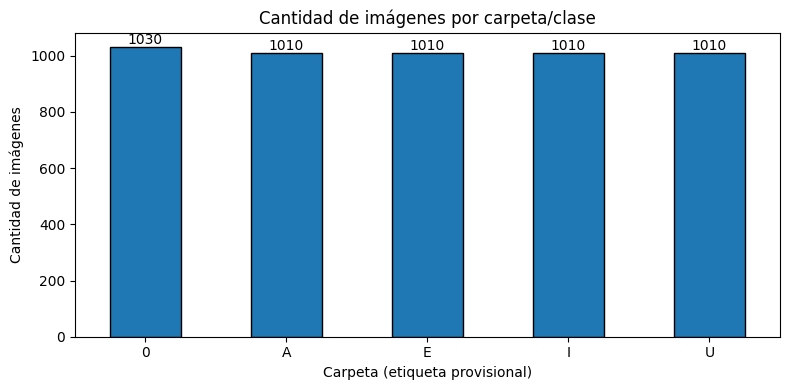

Diferencia entre la clase con más imágenes y la clase con menos imágenes: 20


In [ ]:
serie_conteos = pd.Series(conteos).sort_index()
ax = serie_conteos.plot(kind="bar", figsize=(8, 4), edgecolor="black")
ax.set_title("Cantidad de imágenes por carpeta/clase")
ax.set_xlabel("Carpeta (etiqueta provisional)")
ax.set_ylabel("Cantidad de imágenes")
ax.bar_label(ax.containers[0], fmt="%d")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

if not serie_conteos.empty:
    print("Diferencia entre la clase con más imágenes y la clase con menos imágenes:",
          int(serie_conteos.max() - serie_conteos.min()))

## Visualización aleatoria

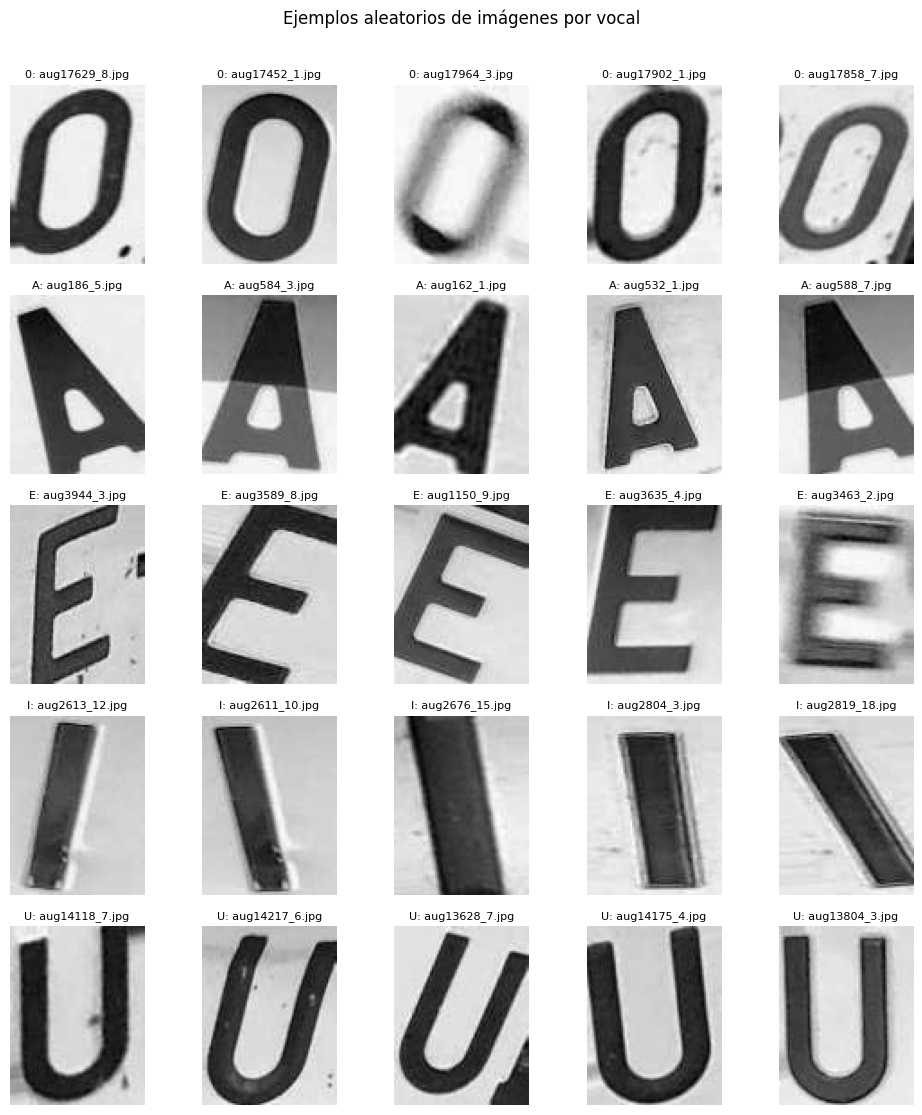

In [ ]:
# Cantidad de imágenes aleatorias por vocal
MUESTRAS_POR_VOCAL = 5

random.seed(42)
# Cada subcarpeta representa una vocal
carpetas = sorted(
    [carpeta for carpeta in RUTA_DATASET.iterdir() if carpeta.is_dir()],
    key=lambda carpeta: carpeta.name
)
imagenes_por_vocal = {}

for carpeta in carpetas:
    imagenes = [
        archivo for archivo in carpeta.iterdir()
        if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_IMAGEN
    ]
    imagenes_por_vocal[carpeta.name] = sorted(imagenes)
vocales = list(imagenes_por_vocal.keys())
cantidades = [len(imagenes_por_vocal[vocal]) for vocal in vocales]
    # 2. Cuadrícula con ejemplos aleatorios de cada vocal
filas = len(vocales)
columnas = MUESTRAS_POR_VOCAL

fig, ejes = plt.subplots(
    filas, columnas,
    figsize=(columnas * 2, filas * 2.2),
    squeeze=False
)
fig.suptitle("Ejemplos aleatorios de imágenes por vocal", y=1.01)
for fila, vocal in enumerate(vocales):
    disponibles = imagenes_por_vocal[vocal]
    seleccionadas = random.sample(
        disponibles, min(MUESTRAS_POR_VOCAL, len(disponibles))
    )

    for columna in range(columnas):
        eje = ejes[fila][columna]
        eje.axis("off")

        if columna < len(seleccionadas):
            ruta_imagen = seleccionadas[columna]
            try:
                with Image.open(ruta_imagen) as imagen:
                    eje.imshow(imagen.copy(), cmap="gray")
                eje.set_title(f"{vocal}: {ruta_imagen.name}", fontsize=8)
            except Exception:
                eje.set_title("No se pudo leer", fontsize=8)

plt.tight_layout()
plt.show()

## Identificación de inconsistencias y calidad de los datos

In [ ]:


print("=== REVISIÓN DE CALIDAD DE DATOS ===")

total_imagenes = 0
archivos_vacios = 0
imagenes_corruptas = 0
duplicados = 0
conteo_clases = {}
hashes_archivos = set()

if not RUTA_DATASET.exists():
    print(f"[ERROR] La ruta '{RUTA_DATASET}' no existe.")
else:
    clases = sorted(
        [carpeta for carpeta in RUTA_DATASET.iterdir() if carpeta.is_dir()],
        key=lambda carpeta: carpeta.name,
    )

    for clase_dir in clases:
        imagenes_clase = [
            archivo
            for archivo in clase_dir.iterdir()
            if archivo.is_file()
            and archivo.suffix.lower() in EXTENSIONES_IMAGEN
        ]

        conteo_clases[clase_dir.name] = len(imagenes_clase)
        total_imagenes += len(imagenes_clase)

        for ruta_img in imagenes_clase:
            if ruta_img.stat().st_size == 0:
                archivos_vacios += 1
                continue

            try:
                with Image.open(ruta_img) as imagen:
                    imagen.verify()

                hash_archivo = hashlib.sha256(
                    ruta_img.read_bytes()
                ).hexdigest()

                if hash_archivo in hashes_archivos:
                    duplicados += 1
                else:
                    hashes_archivos.add(hash_archivo)

            except (UnidentifiedImageError, OSError):
                imagenes_corruptas += 1

    print(f"\n[1] Total de imágenes evaluadas: {total_imagenes}")
    print(f"[2] Archivos vacíos: {archivos_vacios}")
    print(f"[3] Imágenes corruptas o inválidas: {imagenes_corruptas}")
    print(f"[4] Archivos duplicados por contenido: {duplicados}")

    print("\n[5] Distribución de imágenes por clase:")
    for clase, cantidad in sorted(conteo_clases.items()):
        porcentaje = 100 * cantidad / total_imagenes
        print(f"   - Clase '{clase}': {cantidad} imágenes ({porcentaje:.2f} %)")

    if conteo_clases:
        menor_conteo = min(conteo_clases.values())
        mayor_conteo = max(conteo_clases.values())

        if mayor_conteo > 1.5 * menor_conteo:
            print("\n[ALERTA] Se detectó un desbalance importante entre clases.")
        else:
            print("\n[OK] Las clases se encuentran razonablemente equilibradas.")

=== REVISIÓN DE CALIDAD DE DATOS ===

[1] Total de imágenes evaluadas: 5070
[2] Archivos vacíos: 0
[3] Imágenes corruptas o inválidas: 0
[4] Archivos duplicados por contenido: 0

[5] Distribución de imágenes por clase:
   - Clase '0': 1030 imágenes (20.32 %)
   - Clase 'A': 1010 imágenes (19.92 %)
   - Clase 'E': 1010 imágenes (19.92 %)
   - Clase 'I': 1010 imágenes (19.92 %)
   - Clase 'U': 1010 imágenes (19.92 %)

[OK] Las clases se encuentran razonablemente equilibradas.


## Verificación de dimensiones, canales y visualización

--- PROPIEDADES CON PILLOW ---
Ruta del archivo: /content/ocr_vocales/datos/DATASET/U/aug14350_9.jpg
Tamaño (Dimensiones Ancho x Alto): (75, 100)
Modo (Canales/Formato): L

--- FORMA DEL ARREGLO (NUMPY) ---
Forma (Shape) del arreglo: (100, 75)
La imagen está en escala de grises (2 dimensiones: Alto x Ancho).


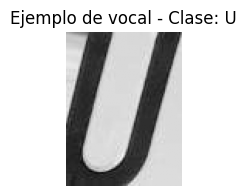

In [ ]:

# Buscar el primer archivo de imagen dentro de las subcarpetas del dataset
archivos_imagen = list(RUTA_DATASET.glob("*/*.*"))
if not archivos_imagen:
  print(f"[ERROR] No se encontraron imágenes en la ruta '{RUTA_DATASET}'")
else:
  # Tomar la primera imagen disponible como muestra
  ruta_ejemplo = archivos_imagen[0]

  # 1. Uso de Pillow (Image.open, size, mode)
  img_pil = Image.open(ruta_ejemplo)
  print("--- PROPIEDADES CON PILLOW ---")
  print(f"Ruta del archivo: {ruta_ejemplo}")
  print(f"Tamaño (Dimensiones Ancho x Alto): {img_pil.size}")
  print(f"Modo (Canales/Formato): {img_pil.mode}")  # 'L' indica escala de grises

  # 2. Conversión a arreglo y verificación de formas (Canales y Dimensiones)
  img_array = np.array(img_pil)
  print("\n--- FORMA DEL ARREGLO (NUMPY) ---")
  print(f"Forma (Shape) del arreglo: {img_array.shape}")
  if len(img_array.shape) == 2:
    print("La imagen está en escala de grises (2 dimensiones: Alto x Ancho).")
  elif len(img_array.shape) == 3:
    print(
        "La imagen es a color (3 dimensiones: Alto x Ancho x Canales RGB/RGBA)."
    )

  # 3. Visualización con Matplotlib (plt.imshow)
  plt.figure(figsize=(5, 2))
  plt.imshow(img_array, cmap="gray" if len(img_array.shape) == 2 else None)
  plt.title(f"Ejemplo de vocal - Clase: {ruta_ejemplo.parent.name}")
  plt.axis("off")
  plt.show()

## Resumen del dataset

In [ ]:
print("\nRESUMEN DEL DATASET")
print(f"Carpetas/clases encontradas: {len(carpetas)}")
print(f"Total de imágenes: {sum(cantidades)}")

for vocal, rutas in imagenes_por_vocal.items():
    dimensiones = {}
    modos = {}
    ilegibles = []

    for ruta in rutas:
        try:
            with Image.open(ruta) as imagen:
                dimensiones[imagen.size] = dimensiones.get(imagen.size, 0) + 1
                modos[imagen.mode] = modos.get(imagen.mode, 0) + 1
                imagen.verify()
        except Exception:
            ilegibles.append(ruta.name)

    print(f"\nCarpeta {vocal}: {len(rutas)} imagenes")
    print(f"  Dimensiones (ancho, alto): {dimensiones}")
    print(f"  Modos de imagen: {modos}")
    print(f"  Archivos ilegibles: {len(ilegibles)}")
    if ilegibles:
        print(f"  Ejemplos de archivos ilegibles: {ilegibles[:5]}")


RESUMEN DEL DATASET
Carpetas/clases encontradas: 5
Total de imágenes: 5070

Carpeta 0: 1030 imagenes
  Dimensiones (ancho, alto): {(75, 100): 1030}
  Modos de imagen: {'L': 1030}
  Archivos ilegibles: 0

Carpeta A: 1010 imagenes
  Dimensiones (ancho, alto): {(75, 100): 1010}
  Modos de imagen: {'L': 1010}
  Archivos ilegibles: 0

Carpeta E: 1010 imagenes
  Dimensiones (ancho, alto): {(75, 100): 1010}
  Modos de imagen: {'L': 1010}
  Archivos ilegibles: 0

Carpeta I: 1010 imagenes
  Dimensiones (ancho, alto): {(75, 100): 1010}
  Modos de imagen: {'L': 1010}
  Archivos ilegibles: 0

Carpeta U: 1010 imagenes
  Dimensiones (ancho, alto): {(75, 100): 1010}
  Modos de imagen: {'L': 1010}
  Archivos ilegibles: 0


# Tratamiento de datos en etapas posteriores

A partir de la inspección realizada, se identificó que las imágenes tienen un tamaño de 75 × 100 píxeles y se encuentran en escala de grises. Para preparar los datos utilizados en los modelos, se aplican las siguientes operaciones:

1. **Escala de grises:** aunque las imágenes revisadas ya se encuentran en este modo, durante el procesamiento se utiliza la conversión a modo `L` para mantener una representación de un canal.

2. **Redimensionamiento:** las imágenes se transforman primero a 75 × 75 píxeles y posteriormente a 32 × 32 píxeles. La reducción permite utilizar menos valores de entrada por imagen, aunque puede modificar sus proporciones y reducir algunos detalles.

3. **Conversión y normalización:** las imágenes se representan mediante arreglos numéricos y sus valores de intensidad se dividen entre 255 para trabajar en el intervalo de 0 a 1.


# Reducción de resolución

Durante la exploración inicial, se identificó que las imágenes poseen variaciones espaciales nativas (con dimensiones originales de $75 \times 100$ píxeles). Para preparar los datos de cara a los algoritmos de aprendizaje automático, esta etapa ejecuta un pipeline de transformación con los siguientes fundamentos técnicos:Estandarización Cuadrada ($75 \times 75$): Se redimensionan las matrices espaciales a un formato uniforme de $75 \times 75$ píxeles. Esto simplifica la estructura de entrada de los datos, permitiendo que cualquier arquitectura de Machine Learning o Red Neuronal procese muestras homogéneas.

Técnica de Interpolación (Lanczos): Para el proceso de redimensionamiento (downscaling), se emplea el algoritmo de interpolación de alta calidad Lanczos (Image.Resampling.LANCZOS). Este método previene efectos de aliasing (dientes de sierra) y preserva de manera óptima los trazos continuos, bordes y la geometría esencial de cada vocal.   Normalización de Píxeles: Los valores de intensidad de los píxeles (originalmente en el rango de $0$ a $255$) son divididos por $255.0$ para escalarlos al intervalo continuo $[0.0, 1.0]$. Esta práctica es indispensable en modelos de Machine Learning para evitar sesgos numéricos debidos a magnitudes grandes y estabilizar la convergencia de los gradientes durante el entrenamiento.

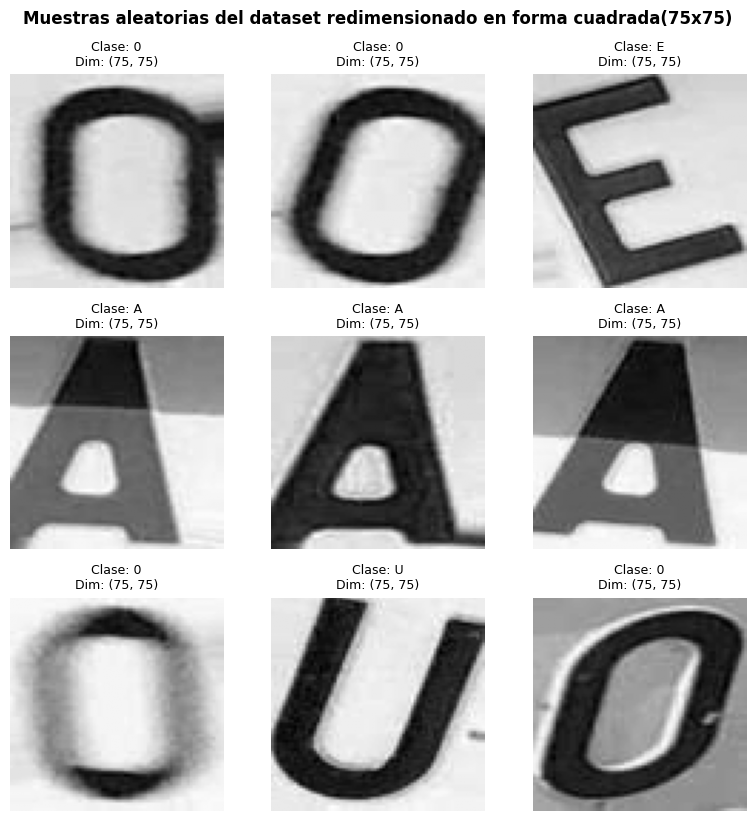

In [ ]:
NUEVO_TAMANO_75 = (75, 75)
X_procesado_75 = []
y_etiquetas_75 = []

clases = list(CLASES_ESPERADAS)

for clase in clases:
  ruta_clase = RUTA_DATASET / clase
  if not ruta_clase.is_dir():
    continue
  imagenes = [
      f
      for f in ruta_clase.iterdir()
      if f.is_file() and f.suffix.lower() in [".png", ".jpg", ".jpeg"]
  ]

  for ruta_img in imagenes:
    try:
      with Image.open(ruta_img) as img:
        img_gris = img.convert("L")
        img_redimensionada = img_gris.resize(
            NUEVO_TAMANO_75, Image.Resampling.LANCZOS
        )
        matriz = np.array(img_redimensionada, dtype=np.float32) / 255.0
        X_procesado_75.append(matriz)
        y_etiquetas_75.append(clase)
    except Exception as e:
      print(f"Error procesando {ruta_img}: {e}")

X_procesado_75 = np.array(X_procesado_75)
y_etiquetas_75 = np.array(y_etiquetas_75)

# Visualización exploratoria a 75x75
num_muestras = min(9, len(X_procesado_75))
indices_aleatorios = random.sample(range(len(X_procesado_75)), num_muestras)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
axes = axes.flatten()

for i, idx in enumerate(indices_aleatorios):
  axes[i].imshow(X_procesado_75[idx], cmap="gray")
  axes[i].set_title(
      f"Clase: {y_etiquetas_75[idx]}\nDim: {X_procesado_75[idx].shape}",
      fontsize=9,
  )
  axes[i].axis("off")

plt.tight_layout()
plt.suptitle(
    "Muestras aleatorias del dataset redimensionado en forma cuadrada(75x75)",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
plt.show()

Una vez aplicado el filtro de escala de grises, la interpolación geométrica y la normalización, es una buena práctica de ingeniería de datos auditar visualmente una muestra aleatoria del dataset resultante. La siguiente visualización en cuadrícula permite comprobar que las vocales retienen sus características morfológicas esenciales y su legibilidad a pesar de la reducción espacial, mitigando posibles distorsiones excesivas antes de alimentar a los modelos de clasificación.

### Optimización y persistencia

Las imágenes en escala de grises se redimensionaron de 75 × 75 a 32 × 32 píxeles para reducir el tamaño de la entrada de los modelos. Con este cambio, cada imagen pasó de 5.625 a 1.024 valores de píxel. Las imágenes redimensionadas se guardaron junto con sus etiquetas en un archivo .npz. En la siguiente sección se muestran algunos ejemplos para observar cómo se ven los caracteres a la nueva resolución.

In [ ]:
NUEVO_TAMANO_32 = (32, 32)
X_procesado_opt = []

print("Reduciendo resolución espacial a 32x32 para optimizar el entrenamiento...")
for matriz in X_procesado_75:
  img_uint8 = (matriz * 255).astype(np.uint8)
  img_pil = Image.fromarray(img_uint8)
  img_redimensionada = img_pil.resize(
      NUEVO_TAMANO_32, Image.Resampling.LANCZOS
  )
  matriz_opt = np.array(img_redimensionada, dtype=np.float32) / 255.0
  X_procesado_opt.append(matriz_opt)

X_procesado_opt = np.array(X_procesado_opt)

# Guardar la versión optimizada a 32x32 en el entorno de Colab
RUTA_SALIDA_NPZ = RUTA_NPZ_32
np.savez_compressed(
    RUTA_SALIDA_NPZ, X=X_procesado_opt, y=y_etiquetas_75
)
print(f"Dataset optimizado 32x32 guardado correctamente en: {RUTA_SALIDA_NPZ}")

RUTA_SALIDA_CARPETA = RUTA_SALIDAS / "DATASET_PROCESADO_32x32"
RUTA_SALIDA_CARPETA.mkdir(parents=True, exist_ok=True)

for i, (matriz, clase) in enumerate(zip(X_procesado_opt, y_etiquetas_75)):
  ruta_clase_salida = RUTA_SALIDA_CARPETA / str(clase)
  ruta_clase_salida.mkdir(parents=True, exist_ok=True)
  img_uint8 = (matriz * 255).astype(np.uint8)
  img_pil_salida = Image.fromarray(img_uint8)
  ruta_archivo_salida = ruta_clase_salida / f"img_proc_32_{i}.png"
  img_pil_salida.save(ruta_archivo_salida)

print(
    "Todas las imágenes optimizadas a 32 × 32 se guardaron "
    "correctamente en el entorno de Colab."
)

Reduciendo resolución espacial a 32x32 para optimizar el entrenamiento...
Dataset optimizado 32x32 guardado correctamente en: /content/ocr_vocales/salidas/DATASET_PROCESADO_32x32.npz
Todas las imágenes optimizadas a 32 × 32 se guardaron correctamente en el entorno de Colab.


### Muestra exploratoria del dataset redimensionado

Dataset 32x32 cargado exitosamente. Forma de X: (5070, 32, 32), y: (5070,)


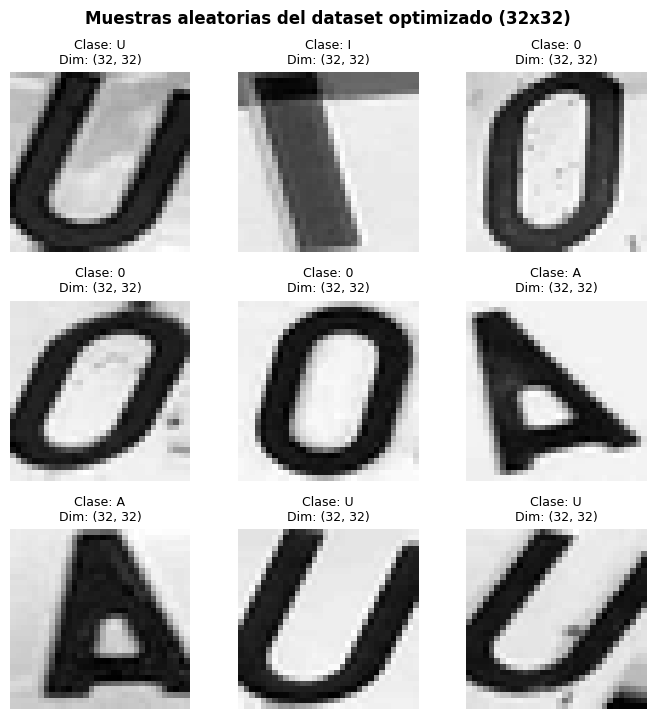

In [ ]:
# 1. Cargar el dataset optimizado a 32x32 desde el entorno de Colab
ruta_npz_32 = RUTA_NPZ_32

if ruta_npz_32.exists():
  data_opt = np.load(ruta_npz_32, allow_pickle=True)
  X_opt = data_opt["X"]
  y_opt = data_opt["y"]

  print(
      f"Dataset 32x32 cargado exitosamente. Forma de X: {X_opt.shape}, y:"
      f" {y_opt.shape}"
  )

  # 2. Seleccionar 9 índices aleatorios de forma segura
  num_muestras = min(9, len(X_opt))
  indices_aleatorios = random.sample(range(len(X_opt)), num_muestras)

  # 3. Configurar la cuadrícula de visualización en escala de grises
  fig, axes = plt.subplots(3, 3, figsize=(7, 7))
  axes = axes.flatten()

  for i, idx in enumerate(indices_aleatorios):
    imagen_matriz = X_opt[idx]
    etiqueta = y_opt[idx]

    axes[i].imshow(imagen_matriz, cmap="gray")
    axes[i].set_title(
        f"Clase: {etiqueta}\nDim: {imagen_matriz.shape}", fontsize=9
    )
    axes[i].axis("off")

  plt.tight_layout()
  plt.suptitle(
      "Muestras aleatorias del dataset optimizado (32x32)",
      fontsize=12,
      fontweight="bold",
      y=1.02,
  )
  plt.show()
else:
  print(
      f"[AVISO] No se encontró el archivo en {ruta_npz_32}. Verifica la ruta o"
      " asegúrate de haber ejecutado la celda de persistencia previa."
  )

### Histogramas de intensidad y contraste

Para complementar la inspección visual de las imágenes redimensionadas a 32 × 32 píxeles, calculamos dos medidas por imagen a partir de sus intensidades en escala de grises, normalizadas entre 0 y 1. La intensidad media es el promedio de los 1.024 píxeles y describe qué tan clara u oscura es la imagen en conjunto. El contraste global se aproxima mediante la desviación estándar de esas intensidades. Un valor mayor indica que en la imagen hay más variación entre tonos claros y oscuros.

Cada histograma agrupa los valores de una de estas medidas. El eje horizontal muestra el valor calculado por imagen y el eje vertical indica cuántas imágenes caen en cada intervalo. Ambas medidas se usan para describir el conjunto de datos durante la exploración.

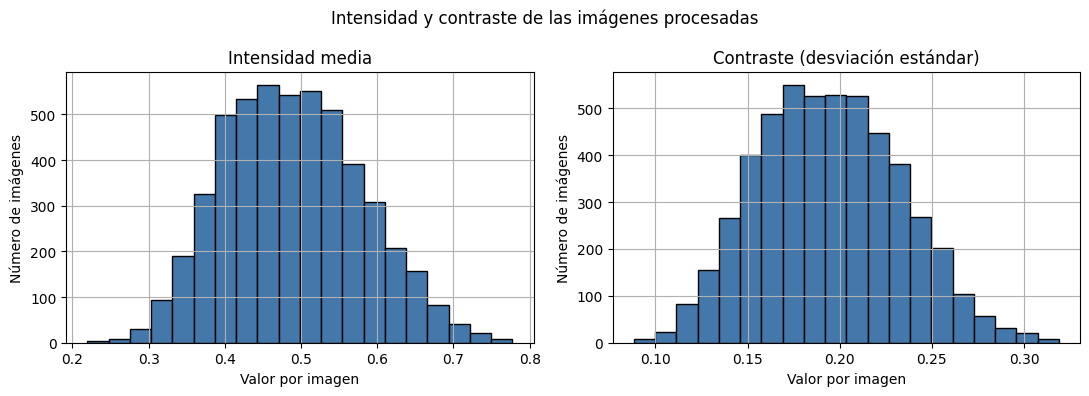

In [ ]:
with np.load(RUTA_NPZ_32) as datos_32:
    imagenes_32 = datos_32["X"]

pixeles_32 = imagenes_32.reshape(len(imagenes_32), -1)

resumen_imagenes = pd.DataFrame({
    "Intensidad media": pixeles_32.mean(axis=1),
    "Contraste (desviación estándar)": pixeles_32.std(axis=1),
})

ejes = resumen_imagenes.hist(
    layout=(1, 2),
    figsize=(11, 4),
    bins=20,
    color="#4477AA",
    edgecolor="black",
)

for ax in ejes.ravel():
    ax.set_xlabel("Valor por imagen")
    ax.set_ylabel("Número de imágenes")

plt.suptitle("Intensidad y contraste de las imágenes procesadas")
plt.tight_layout()
plt.show()

Interpretación de los histogramas

Las barras más altas de intensidad media se concentran aproximadamente entre 0,40 y 0,55, mientras que las de contraste global se concentran entre 0,16 y 0,23. En ambos histogramas hay menos imágenes hacia los extremos. Esto muestra que, incluso después de llevar todas las imágenes al mismo tamaño y rango de intensidad, persisten diferencias de luminosidad y de contraste entre ellas.

Como los histogramas reúnen todas las clases, describen la variación general del conjunto. Para saber si alguna de estas medidas difiere entre vocales, habría que examinar sus distribuciones por clase.

## Intensidad y contraste por vocal

Los histogramas anteriores muestran cómo se distribuyen la intensidad media y el contraste global al reunir todas las imágenes. Para examinar si estas medidas presentan diferencias entre vocales, se construye un diagrama de caja para cada medida. La línea dentro de cada caja indica la mediana y la caja abarca el 50 % central de los valores. Esto permite comparar el centro, la dispersión y el solapamiento de las distribuciones entre clases.

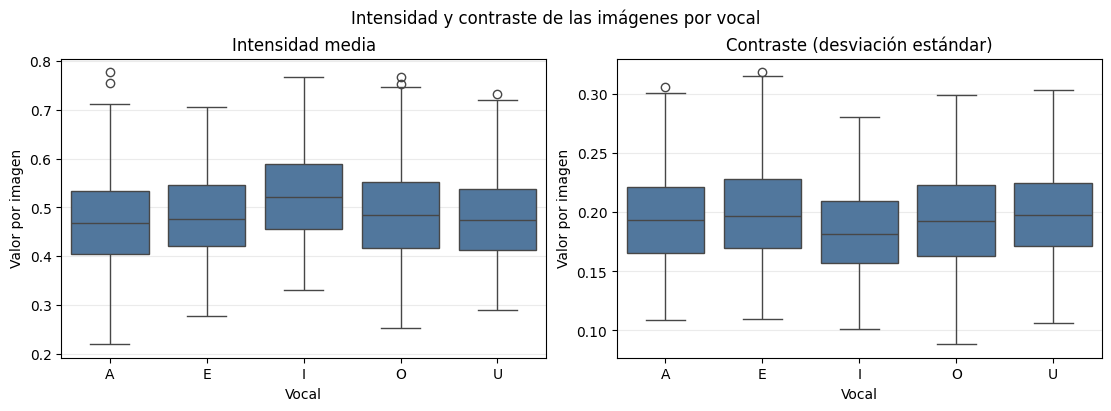

In [ ]:
with np.load(RUTA_NPZ_32) as datos_32:
    etiquetas_32 = datos_32["y"].ravel()

resumen_por_vocal = resumen_imagenes.copy()
resumen_por_vocal["Vocal"] = (
    pd.Series(etiquetas_32).astype(str).replace({"0": "O"})
)

orden_vocales = ["A", "E", "I", "O", "U"]
medidas = ["Intensidad media", "Contraste (desviación estándar)"]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

for ax, medida in zip(ejes, medidas):
    sns.boxplot(
        data=resumen_por_vocal,
        x="Vocal",
        y=medida,
        order=orden_vocales,
        color="#4477AA",
        ax=ax,
    )
    ax.set_title(medida)
    ax.set_ylabel("Valor por imagen")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Intensidad y contraste de las imágenes por vocal")
plt.show()

Interpretación de los diagramas de caja

La vocal I presenta la mediana más alta de intensidad media, cercana a 0,52, y la mediana más baja de contraste global, cercana a 0,18. En este conjunto, sus imágenes tienden a ser más claras en promedio y a presentar menor variación entre las intensidades de sus píxeles. Las otras cuatro vocales muestran medianas más próximas entre sí en ambas medidas.

Las cajas de las cinco vocales se solapan en ambos gráficos. Esto indica que distintos caracteres pueden tener niveles similares de intensidad y contraste. Estas medidas ayudan a describir las imágenes, pero por sí solas ofrecen una separación limitada entre clases. Para reconocer las vocales también importa cómo se distribuyen los píxeles y qué forma dibujan.

## Justificación del redimensionamiento a 32 × 32 píxeles

Las imágenes en escala de grises se redimensionaron de 75 × 75 a 32 × 32 píxeles para reducir el tamaño de la entrada de los modelos. La elección de esta resolución se justifica a partir de dos aspectos.

1. **Reducción de dimensionalidad.** Cada imagen pasó de 5.625 a 1.024 valores de píxel, lo que representa una reducción del 81,8 %. Para los modelos que usan PCA, estos 1.024 valores se organizan en un vector sobre el que se aplica la reducción a componentes principales. La red neuronal convolucional (CNN) recibe la imagen como una cuadrícula de 32 × 32 píxeles con un solo canal.

2. **Legibilidad y pérdida de detalle.** En la muestra visualizada, las vocales siguen siendo reconocibles a 32 × 32 píxeles, aunque el redimensionamiento puede eliminar detalles finos de los trazos. Para determinar cómo influye este cambio en el desempeño o en el sobreajuste de los modelos, habría que comparar ambas resoluciones bajo el mismo protocolo de evaluación.

Las imágenes redimensionadas y sus etiquetas se guardaron en el archivo `DATASET_PROCESADO_32x32.npz`, que se utiliza como base para el entrenamiento y la evaluación de los modelos.

# Diseño de experimentos y entrenamiento de modelos

El experimento compara cinco modelos de clasificación supervisada para el reconocimiento de vocales a partir de imágenes de 32 × 32 píxeles.

1. **División de los datos.** Las 5.070 imágenes se dividieron en 4.056 para entrenamiento (80 %) y 1.014 para prueba (20 %). La división se hizo de forma estratificada, con semilla 42, para conservar aproximadamente la proporción de cada vocal en ambos conjuntos. Los cinco modelos usan la misma división.

2. **Representación de las imágenes**. Random Forest, el árbol de decisión, el perceptrón multicapa (MLP) y la regresión logística multiclase (Softmax) utilizan los 94 componentes principales obtenidos mediante PCA. La CNN utiliza directamente las imágenes de 32 × 32 píxeles con un canal, conservando su estructura espacial.

3. **Búsqueda de hiperparámetros y evaluación.** Las configuraciones incluidas en cada búsqueda con `GridSearchCV` se comparan mediante validación cruzada de cinco particiones sobre el conjunto de entrenamiento, usando la exactitud (*accuracy*) como criterio. El conjunto de prueba se utiliza para la evaluación final mediante la exactitud, el reporte de clasificación por vocal y la matriz de confusión.

In [ ]:
# 1. Cargar el dataset optimizado a 32x32 desde el entorno de Colab
ruta_npz_32 = RUTA_NPZ_32
data_opt = np.load(ruta_npz_32, allow_pickle=True)

X_opt = data_opt["X"]  # Forma esperada: (5070, 32, 32)
y_opt = data_opt["y"]  # Etiquetas de las vocales ('0', 'A', 'E', 'I', 'U')

print(f"Dimensiones cargadas - X: {X_opt.shape}, y: {y_opt.shape}")

# 2. Aplanar las imágenes de 32x32 a vectores unidimensionales de 1024 características
n_muestras = X_opt.shape[0]
X_flat = X_opt.reshape(n_muestras, -1)
print(f"Forma de la matriz aplanada (X_flat): {X_flat.shape}")

# 3. Codificar las etiquetas categóricas a valores numéricos enteros
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_opt)

# 4. División Train/Test estratificada (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X_flat, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print(f"Conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Conjunto de prueba (X_test): {X_test.shape}")

Dimensiones cargadas - X: (5070, 32, 32), y: (5070,)
Forma de la matriz aplanada (X_flat): (5070, 1024)
Conjunto de entrenamiento (X_train): (4056, 1024)
Conjunto de prueba (X_test): (1014, 1024)


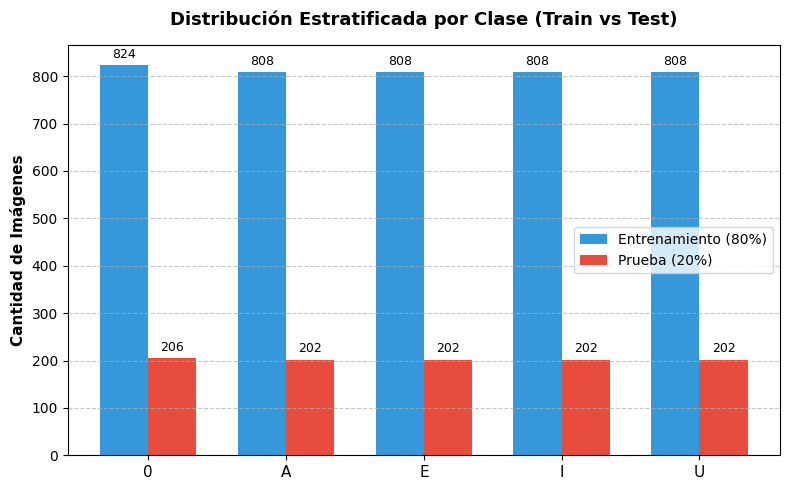

In [ ]:
# Contar la frecuencia de cada clase en y_train y y_test
clases_unicas = np.unique(y_encoded)
nombres_clases = label_encoder.classes_

conteo_train = [np.sum(y_train == c) for c in clases_unicas]
conteo_test = [np.sum(y_test == c) for c in clases_unicas]

# Configurar la gráfica de barras agrupadas
x = np.arange(len(nombres_clases))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(
    x - ancho/2, conteo_train, ancho, label='Entrenamiento (80%)', color='#3498db'
)
rects2 = ax.bar(
    x + ancho/2, conteo_test, ancho, label='Prueba (20%)', color='#e74c3c'
)

# Etiquetas y diseño académico
ax.set_ylabel('Cantidad de Imágenes', fontsize=11, fontweight='bold')
ax.set_title(
    'Distribución Estratificada por Clase (Train vs Test)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xticks(x)
ax.set_xticklabels(nombres_clases, fontsize=11)
ax.legend(fontsize=10)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Mostrar valores exactos sobre las barras
def autolabel(rects):
  for rect in rects:
    height = rect.get_height()
    ax.annotate(
        f'{height}',
        xy=(rect.get_x() + rect.get_width() / 2, height),
        xytext=(0, 3),  # 3 points vertical offset
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=9,
    )

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

# División de datos y reducción de dimensionalidad (PCA)

Después de la división estratificada, se aplicó el análisis de componentes principales (PCA) a las imágenes aplanadas para reducir las 1.024 variables de píxel a un conjunto de componentes que conserva al menos el 95 % de la varianza del conjunto de entrenamiento. Esta transformación produjo 94 componentes principales, utilizados como entrada por la regresión logística multiclase, Random Forest, el árbol de decisión y el perceptrón multicapa. La CNN no utiliza PCA, ya que procesa directamente las imágenes de 32 × 32 píxeles para conservar su estructura espacial.

El PCA se ajustó con las 4.056 imágenes de entrenamiento. Luego se utilizó esa misma transformación en las 1.014 imágenes de prueba. Así, el conjunto de prueba quedó fuera del ajuste del PCA.

**Alcance de la validación cruzada.** El PCA se ajustó una sola vez, antes de la búsqueda de hiperparámetros. Por eso, las imágenes de las particiones internas de validación también contribuyeron al cálculo de los componentes. Para evaluar el preprocesamiento y el modelo juntos dentro de cada partición, el PCA tendría que ajustarse dentro de la validación cruzada mediante un `Pipeline`.

In [ ]:
# ======================================================================
#                              APLICACIÓN DE PCA
# ======================================================================

print("--- Iniciando Reducción de Dimensionalidad con PCA ---")
inicio_pca = time.time()

# 1. Instanciamos el PCA para que retenga el 95% de la varianza explicada.
pca = PCA(n_components=0.95, random_state=42)

# 2. Ajustamos el PCA SOLO con los datos de entrenamiento (X_train)
# y transformamos AMBOS conjuntos (Train y Test)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test) # Al conjunto de datos de prueba solo lo transformamos, NO hacemos fit.


tiempo_fin_pca = time.time() - inicio_pca

print(f"PCA completado en {tiempo_fin_pca:.2f} segundos.")
print(f"Dimensiones de X_train ANTES de PCA: {X_train.shape[1]} características (pixeles)")
print(f"Dimensiones de X_train DESPUÉS de PCA: {X_train_pca.shape[1]} componentes principales")
print(f"Dimensiones de X_test DESPUÉS de PCA: {X_test_pca.shape[1]} componentes principales")
print(f"Varianza total explicada retenida: {np.sum(pca.explained_variance_ratio_)*100:.2f}%")

# 4. Guardado de los archivos para las siguientes etapas
print("\n--- Guardando archivos para persistencia ---")
RUTA_MODELOS.mkdir(parents=True, exist_ok=True)

ruta_pca = RUTA_MODELOS / "pca_transform.pkl"
ruta_datos_pca = RUTA_MODELOS / "datos_transformados_pca.npz"

# Guardar el modelo PCA
joblib.dump(pca, ruta_pca)

# Guardar los arreglos transformados para que los modelos los consuman después
np.savez_compressed(
    ruta_datos_pca,
    X_train_pca=X_train_pca,
    X_test_pca=X_test_pca,
    y_train=y_train,
    y_test=y_test
)

print(f"Transformación PCA guardada en el entorno de Colab: {ruta_pca.name}")
print(f"Conjuntos de datos transformados guardados exitosamente en: {ruta_datos_pca.name}")

--- Iniciando Reducción de Dimensionalidad con PCA ---
PCA completado en 2.33 segundos.
Dimensiones de X_train ANTES de PCA: 1024 características (pixeles)
Dimensiones de X_train DESPUÉS de PCA: 94 componentes principales
Dimensiones de X_test DESPUÉS de PCA: 94 componentes principales
Varianza total explicada retenida: 95.04%

--- Guardando archivos para persistencia ---
Transformación PCA guardada en el entorno de Colab: pca_transform.pkl
Conjuntos de datos transformados guardados exitosamente en: datos_transformados_pca.npz


# Random Forest

Para dar inicio a la experimentación con algoritmos de aprendizaje supervisado, se selecciona el modelo de ensamblaje **Random Forest**, el cual construye múltiples árboles de decisión y combina sus resultados para mejorar la precisión y evitar el sobreajuste.

**Procedimiento experimental:**
* **Búsqueda en Malla (`GridSearchCV`):** Se evalúan de forma sistemática diferentes combinaciones de hiperparámetros (número de árboles o `n_estimators`, profundidad máxima `max_depth` y división mínima de muestras `min_samples_split`).
* **Validación Cruzada (`cv=5`):** El conjunto de entrenamiento se divide en 5 particiones para entrenar y validar iterativamente, garantizando que los hiperparámetros seleccionados sean robustos y generalizables.
* **Evaluación Independiente:** El mejor modelo resultante se somete a prueba utilizando el conjunto de datos aislado (`X_test`), generando un reporte de clasificación detallado (*accuracy*, *precision*, *recall* y *F1-score* por clase).

### Configuración de la búsqueda de hiperparámetros




In [ ]:
# Malla ampliada incluyendo los hiperparámetros de la diapositiva de clase
param_grid_rf_completo = {
    'n_estimators': [50,100, 150],
    'max_depth': [3, 4, 5],
    'min_samples_split': [2,5],
    'min_samples_leaf': [1, 2, 3],      # Mínimo de muestras por hoja
    'max_features': [2, 3, 4]           # Variables candidatas por división
}

rf_base = RandomForestClassifier(random_state=42)

# GridSearchCV con la nueva malla ampliada
grid_search_rf = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf_completo,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
print("Configuración de Random Forest y malla de hiperparámetros listas.")


Configuración de Random Forest y malla de hiperparámetros listas.


### Entrenamiento del bosque ajustado

In [ ]:
print("Iniciando entrenamiento con malla ampliada (sobre datos PCA)...")
inicio = time.time()

# Utilizamos los datos de entrenamiento transformados por PCA
grid_search_rf.fit(X_train_pca, y_train)

tiempo_fin = time.time() - inicio
print(f"¡Finalizado en {tiempo_fin:.2f} segundos!")
print(f"Mejores hiperparámetros: {grid_search_rf.best_params_}")
print(f"Mejor precisión (cv=5): {grid_search_rf.best_score_:.4f}")

# Extraer el mejor modelo para tenerlo listo
mejor_modelo_rf = grid_search_rf.best_estimator_

Iniciando entrenamiento con malla ampliada (sobre datos PCA)...
Fitting 5 folds for each of 162 candidates, totalling 810 fits
¡Finalizado en 495.61 segundos!
Mejores hiperparámetros: {'max_depth': 5, 'max_features': 3, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 150}
Mejor precisión (cv=5): 0.9827


### Resultados de la búsqueda de hiperparámetros

In [ ]:
resultados_malla_rf = pd.DataFrame(grid_search_rf.cv_results_)
mejores_configuraciones_rf = resultados_malla_rf.sort_values(
    "rank_test_score", kind="stable"
).head(10)

display(mejores_configuraciones_rf[[
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
    "param_max_features",
    "mean_test_score",
    "std_test_score",
]].rename(columns={
    "param_n_estimators": "Árboles",
    "param_max_depth": "Profundidad máxima",
    "param_min_samples_split": "Mínimo para dividir",
    "param_min_samples_leaf": "Mínimo por hoja",
    "param_max_features": "Variables por división",
    "mean_test_score": "Exactitud media",
    "std_test_score": "Desviación estándar",
}).style.format({
    "Exactitud media": "{:.2%}",
    "Desviación estándar": lambda valor: f"{valor * 100:.2f} pp",
}))

,Árboles,Profundidad máxima,Mínimo para dividir,Mínimo por hoja,Variables por división,Exactitud media,Desviación estándar
140,150,5,2,3,3,98.27%,0.51 pp
143,150,5,5,3,3,98.27%,0.51 pp
128,150,5,2,1,3,98.27%,0.83 pp
155,150,5,5,2,4,98.23%,0.55 pp
149,150,5,5,1,4,98.22%,0.63 pp
152,150,5,2,2,4,98.15%,0.68 pp
158,150,5,2,3,4,98.13%,0.65 pp
161,150,5,5,3,4,98.13%,0.65 pp
131,150,5,5,1,3,98.10%,0.48 pp
154,100,5,5,2,4,98.08%,0.63 pp


###	Visualización de un árbol del bosque ajustado



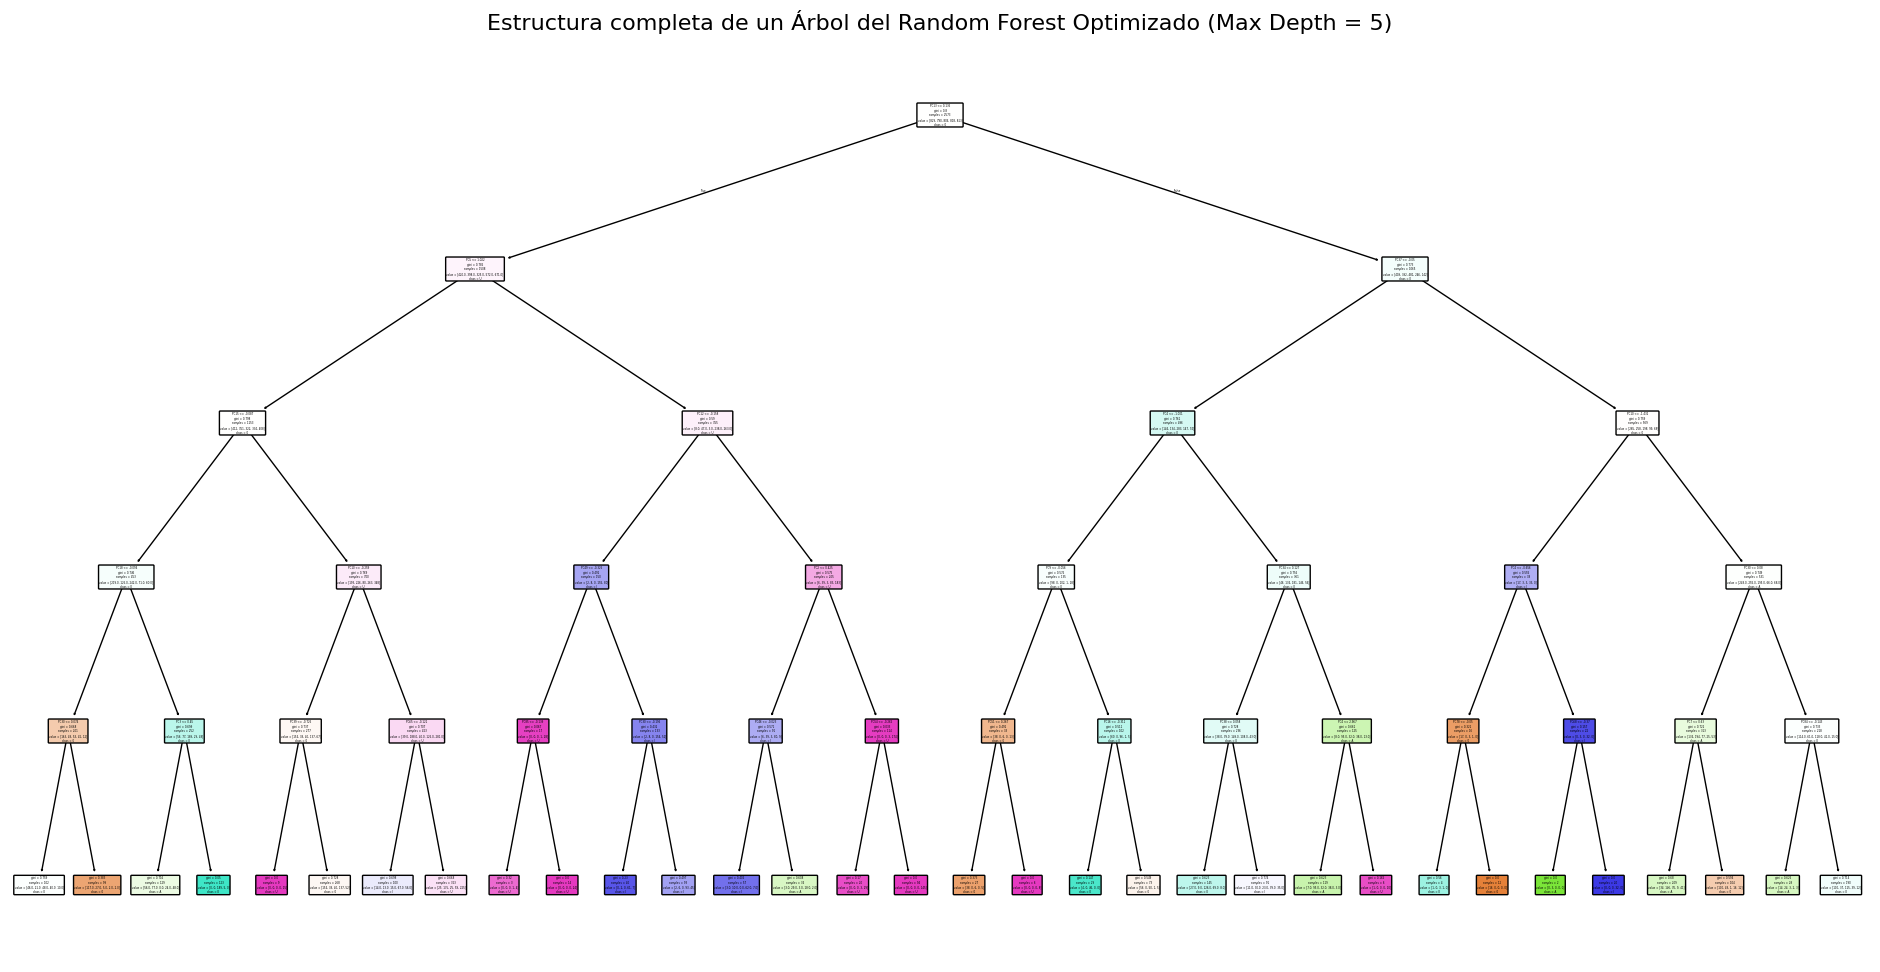

In [ ]:
# Extraemos el primer árbol del bosque optimizado
arbol_optimizado = mejor_modelo_rf.estimators_[0]

plt.figure(figsize=(24, 12))

plot_tree(
    arbol_optimizado,
    max_depth=5,                      # Como su profundidad máxima es 5, lo veremos completo
    filled=True,                      # Colores para distinguir las clases
    rounded=True,                     # Estética limpia
    feature_names=[f"PC{i + 1}" for i in range(X_train_pca.shape[1])],
    class_names=label_encoder.classes_
)

plt.title("Estructura completa de un Árbol del Random Forest Optimizado (Max Depth = 5)", fontsize=16)
plt.show()

## Evaluación del Random Forest seleccionado en el conjunto de prueba

Después de seleccionar los mejores hiperparámetros mediante validación cruzada, el Random Forest se evaluó sobre X_test_pca. La transformación PCA había sido ajustada previamente utilizando únicamente las 4.056 imágenes de entrenamiento y posteriormente se aplicó al conjunto de prueba, sin volver a ajustarla. De esta manera, las 1.014 imágenes de prueba permanecieron aisladas hasta la evaluación final.

=== REPORTE DE CLASIFICACIÓN (Modelo Optimizado) ===
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       206
           A       1.00      0.99      0.99       202
           E       0.99      1.00      1.00       202
           I       0.99      0.99      0.99       202
           U       1.00      1.00      1.00       202

    accuracy                           0.99      1014
   macro avg       0.99      0.99      0.99      1014
weighted avg       0.99      0.99      0.99      1014



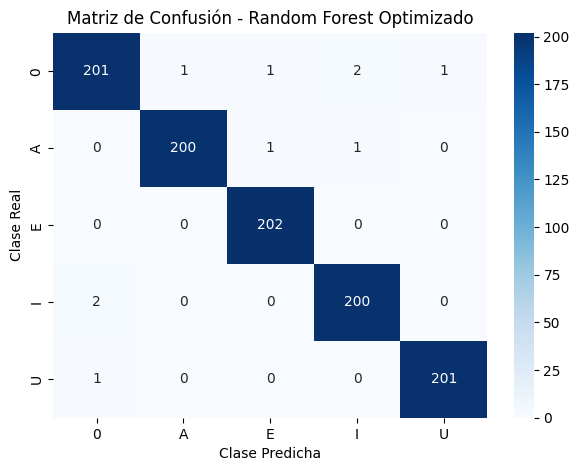

In [ ]:
# 1. Predecir utilizando el mejor modelo optimizado que ya guardó GridSearchCV
y_pred_optimo = mejor_modelo_rf.predict(X_test_pca)

# 2. Imprimir la tabla con el reporte de clasificación detallado
print("=== REPORTE DE CLASIFICACIÓN (Modelo Optimizado) ===")
print(classification_report(y_test, y_pred_optimo, target_names=label_encoder.classes_))

# 3. Generar la Matriz de Confusión en formato de tabla visual (mapa de calor)
cm = confusion_matrix(y_test, y_pred_optimo)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Matriz de Confusión - Random Forest Optimizado")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()

## Conclusión y análisis de resultados

El Random Forest optimizado mediante GridSearchCV alcanzó una exactitud de 99,01 % y un F1 macro de 99,02 % sobre las 1.014 imágenes del conjunto de prueba, con un total de 10 clasificaciones incorrectas. El reporte por clase muestra un rendimiento equilibrado, con valores de precisión, sensibilidad y F1 cercanos o iguales a 1,00 en las cinco vocales.

La diferencia entre la exactitud de entrenamiento (99,46 %) y la exactitud de prueba (99,01 %) fue de 0,45 puntos porcentuales, por lo que no se observa una señal pronunciada de sobreajuste en esta partición. Su desempeño lo posiciona como un modelo competitivo, aunque quedó por debajo del MLP, la CNN y Softmax en la comparación final.

GridSearchCV reajustó automáticamente la mejor configuración utilizando todo el conjunto de entrenamiento antes de su evaluación final.

## Guardado del modelo Random Forest seleccionado

El Random Forest seleccionado se guarda con joblib en el archivo random_forest_model.pkl. La transformación PCA se conserva por separado en pca_transform.pkl. Para realizar predicciones con imágenes nuevas, primero debe aplicarse el mismo preprocesamiento y la transformación PCA antes de entregarlas al modelo.

In [ ]:


ruta_rf_final = RUTA_MODELOS / "random_forest_model.pkl"

joblib.dump(mejor_modelo_rf, ruta_rf_final)

print(f"Random Forest seleccionado guardado correctamente en: {ruta_rf_final}")

Random Forest seleccionado guardado correctamente en: /content/ocr_vocales/salidas/MODELS/random_forest_model.pkl


# Árbol de decisión

Un árbol de decisión clasifica cada imagen mediante una serie de reglas. En cada nodo interno, el árbol divide las muestras según el valor de una característica. Al llegar a una hoja, asigna una clase.

Al igual que con Random Forest, se utiliza GridSearchCV para evaluar sistemáticamente las combinaciones de hiperparámetros mediante validación cruzada. El entrenamiento se realiza con X_train_pca, que contiene los 94 componentes principales obtenidos previamente a partir del conjunto de entrenamiento.

## Configuración de la búsqueda de hiperparámetros

In [ ]:
# Instanciar el modelo base
dt_base = DecisionTreeClassifier(random_state=42)

# Definir la malla de hiperparámetros a explorar
param_grid_dt = {
    'criterion': ['gini', 'entropy'],      # Medida de calidad de la división
    'max_depth': [10, 15, 20, None],       # Profundidad máxima del árbol
    'min_samples_split': [2, 5, 10],       # Mínimo de muestras para dividir un nodo
    'min_samples_leaf': [1, 2, 4]          # Mínimo de muestras en una hoja
}

# Configurar GridSearchCV con validación cruzada (cv=5)
grid_search_dt = GridSearchCV(
    estimator=dt_base,
    param_grid=param_grid_dt,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

La malla combina dos criterios de división (Gini y entropía), cuatro opciones de profundidad máxima y tres valores para cada uno de los mínimos de muestras por nodo y por hoja. En total, `GridSearchCV` compara 72 configuraciones mediante validación cruzada de cinco particiones, usando la exactitud media como criterio de selección.

Esta búsqueda utiliza las imágenes de entrenamiento transformadas previamente mediante PCA (X_train_pca). Como PCA fue ajustado antes de las particiones internas de la validación cruzada, los resultados deben interpretarse considerando esta limitación metodológica. Aun así, la mejor configuración identificada por GridSearchCV corresponde al árbol utilizado en la evaluación final. El conjunto de prueba permaneció completamente aislado durante la selección de hiperparámetros.

Se ejecutó `GridSearchCV` sobre los datos de entrenamiento transformados con PCA (`X_train_pca`). Se evaluaron las 72 configuraciones de la malla mediante validación cruzada de cinco particiones y se seleccionó la que obtuvo la mayor exactitud media.

In [ ]:

print("--- Iniciando optimización de Árbol de Decisión ---")
inicio_dt = time.time()

# Ajustar el modelo usando los datos de entrenamiento con dimensionalidad reducida
grid_search_dt.fit(X_train_pca, y_train)

tiempo_fin_dt = time.time() - inicio_dt
print(f"Entrenamiento finalizado en {tiempo_fin_dt:.2f} segundos.")
print(f"Mejores hiperparámetros encontrados: {grid_search_dt.best_params_}")
print(f"Mejor exactitud media en validación cruzada: {grid_search_dt.best_score_:.4f}")

# Extraer el mejor modelo
mejor_modelo_dt = grid_search_dt.best_estimator_

--- Iniciando optimización de Árbol de Decisión ---
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Entrenamiento finalizado en 163.49 segundos.
Mejores hiperparámetros encontrados: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5}
Mejor exactitud media en validación cruzada: 0.9381


## Evaluación del modelo
Probamos  el modelo optimizado utilizando exclusivamente los datos de prueba (X_test_pca), los cuales se mantuvieron aislados durante todo el proceso de entrenamiento.


=== REPORTE DE CLASIFICACIÓN (ÁRBOL DE DECISIÓN) ===
              precision    recall  f1-score   support

           0       0.93      0.94      0.93       206
           A       0.96      0.98      0.97       202
           E       0.98      0.98      0.98       202
           I       0.97      0.92      0.94       202
           U       0.93      0.96      0.94       202

    accuracy                           0.95      1014
   macro avg       0.95      0.95      0.95      1014
weighted avg       0.95      0.95      0.95      1014



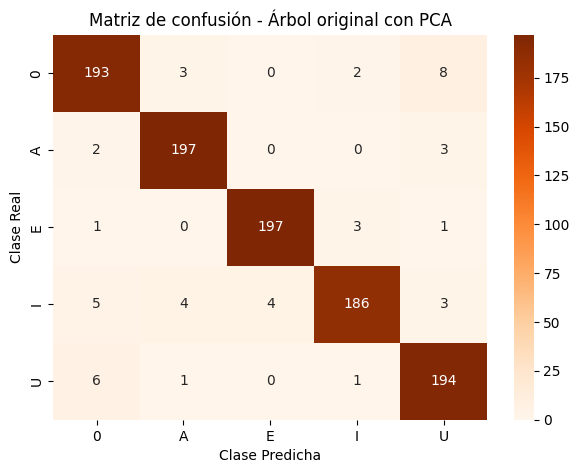

In [ ]:
# Predecir sobre el conjunto de prueba
y_pred_dt = mejor_modelo_dt.predict(X_test_pca)

# Imprimir el reporte
print("\n=== REPORTE DE CLASIFICACIÓN (ÁRBOL DE DECISIÓN) ===")
print(classification_report(y_test, y_pred_dt, target_names=label_encoder.classes_))

# Generar y graficar la matriz de confusión
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Oranges',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Matriz de confusión - Árbol original con PCA")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()

##Visualización y Análisis de Ajuste

In [ ]:
# Análisis de Ajuste (Overfitting vs Appropriate-fitting)
# Evaluamos en el conjunto de entrenamiento
y_pred_dt_train = mejor_modelo_dt.predict(X_train_pca)
acc_train = accuracy_score(y_train, y_pred_dt_train)
# Evaluamos en el conjunto de prueba aislado
y_pred_dt_test = mejor_modelo_dt.predict(X_test_pca)
acc_test = accuracy_score(y_test, y_pred_dt_test)

print("\n--- Análisis de Sobreajuste (Overfitting) ---")
print(f"Precisión en Entrenamiento (Train Accuracy): {acc_train:.4f}")
print(f"Precisión en Prueba (Test Accuracy): {acc_test:.4f}")
print(f"Diferencia de rendimiento: {abs(acc_train - acc_test):.4f}")


--- Análisis de Sobreajuste (Overfitting) ---
Precisión en Entrenamiento (Train Accuracy): 0.9975
Precisión en Prueba (Test Accuracy): 0.9536
Diferencia de rendimiento: 0.0439


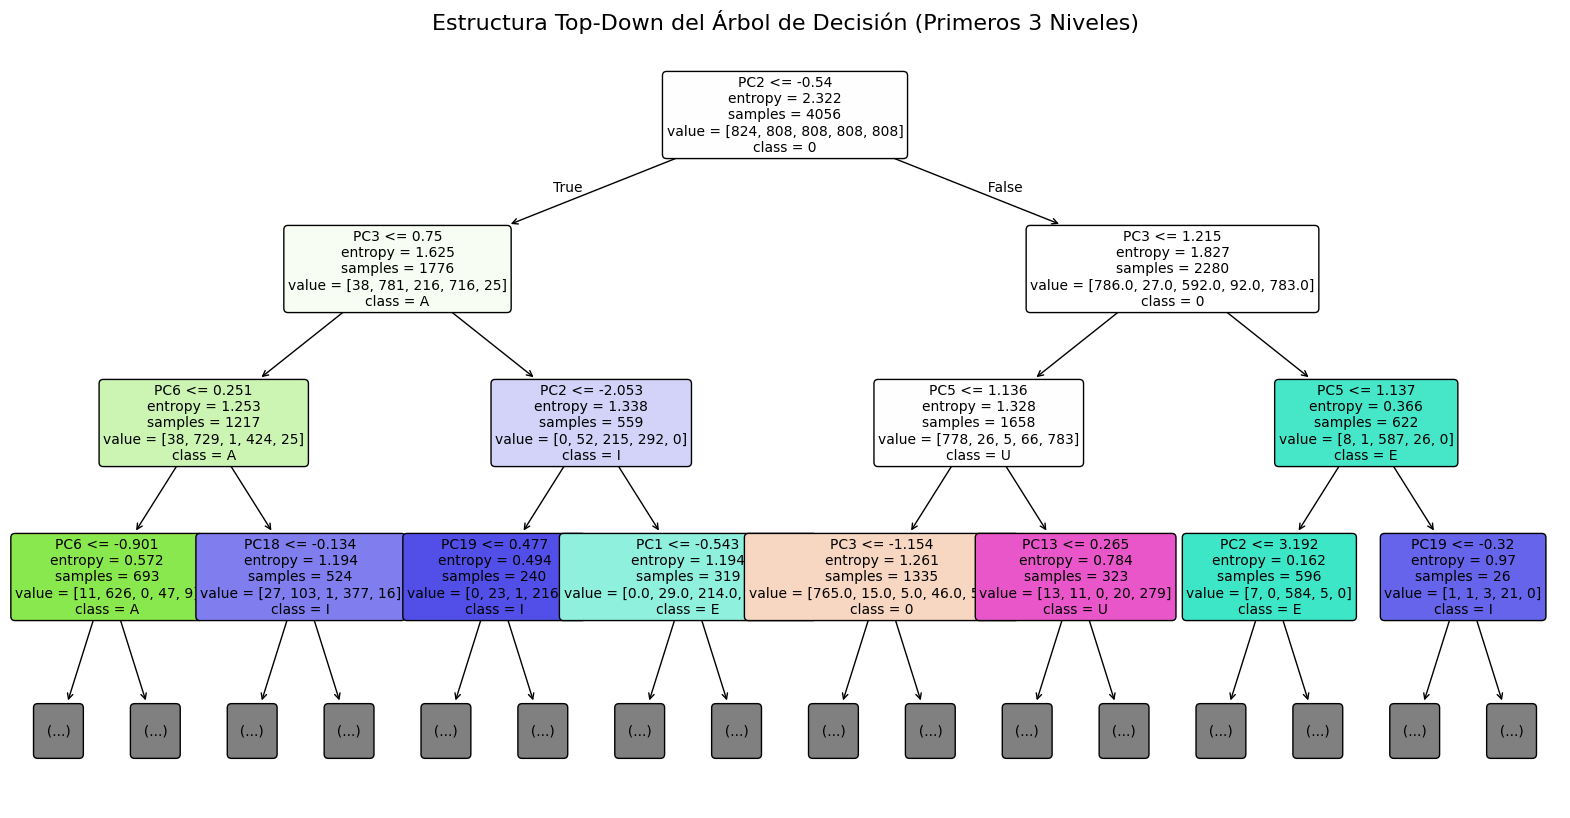

In [ ]:
# Visualización del Árbol de Decisión
# Limitamos el 'max_depth' en el plot para que la imagen sea legible
plt.figure(figsize=(20, 10))
plot_tree(
    mejor_modelo_dt,
    max_depth=3, # Mostramos solo los primeros 3 niveles para claridad visual
    feature_names=[f"PC{i+1}" for i in range(X_train_pca.shape[1])],
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura Top-Down del Árbol de Decisión (Primeros 3 Niveles)", fontsize=16)
plt.show()

## Conclusión y análisis de resultados

El árbol de decisión optimizado mediante GridSearchCV alcanzó una exactitud de 95,36 % y un F1 macro de 95,37 % sobre las 1.014 imágenes del conjunto de prueba, cometiendo 47 errores de clasificación. Aunque obtuvo un desempeño elevado, presentó el resultado más bajo entre los cinco modelos evaluados.

La exactitud disminuyó de 99,75 % en entrenamiento a 95,36 % en prueba, una diferencia de 4,39 puntos porcentuales. Esta separación indica una mayor tendencia al sobreajuste que en los demás modelos. El resultado también evidencia que un árbol individual posee menor capacidad para representar la variedad de trazos manuscritos que los métodos de ensamble y las redes neuronales evaluadas.

## Persistencia del modelo

El mejor modelo del árbol de decisión se guardó con `joblib` en el archivo `decision_tree_model.pkl`, dentro del entorno local de Colab. .

In [ ]:
ruta_dt = RUTA_MODELOS / "decision_tree_model.pkl"
joblib.dump(mejor_modelo_dt, ruta_dt)

print(f"Árbol seleccionado guardado en: {ruta_dt}")

Árbol seleccionado guardado en: /content/ocr_vocales/salidas/MODELS/decision_tree_model.pkl


# Red neuronal de tipo perceptrón multicapa (MLP)

El perceptrón multicapa es una red neuronal que combina las características de entrada en una o más capas ocultas para clasificar cada imagen en una de las cinco clases del proyecto. En este experimento, la red recibe los 94 componentes principales obtenidos a partir de las imágenes de 32 × 32 píxeles.

Con `GridSearchCV` se comparan 18 configuraciones que varían la arquitectura de las capas ocultas, la regularización y la tasa de aprendizaje inicial. La configuración se selecciona por su exactitud media en cinco particiones de validación cruzada y se evalúa después en el conjunto de prueba.

## Carga de los datos transformados

Se importan las bibliotecas para configurar, entrenar y evaluar el perceptrón multicapa. También se cargan el PCA ya ajustado y los conjuntos de entrenamiento y prueba transformados en la etapa de preprocesamiento. Cada imagen está representada por 94 componentes principales, que se usan como entrada de la red.



In [ ]:
# --- Carga del PCA y Datos guardados (por reinicio del entorno) ---
ruta_pca = RUTA_MODELOS / "pca_transform.pkl"
ruta_datos = RUTA_MODELOS / "datos_transformados_pca.npz"

# 1. Si el pca ya está en memoria de los pasos anteriores, esta línea sirve como respaldo
pca = joblib.load(ruta_pca)
print("Dependencias importadas y modelo PCA cargado exitosamente desde el entorno de Colab.")

# 2. Cargar y sobrescribir los conjuntos de datos transformados
# Cargar la transformación PCA guardada durante el preprocesamiento
datos_cargados = np.load(ruta_datos)

X_train_pca = datos_cargados['X_train_pca']
X_test_pca = datos_cargados['X_test_pca']
y_train = datos_cargados['y_train']
y_test = datos_cargados['y_test']

print(f"Datos cargados desde el entorno de Colab. Dimensiones de X_train_pca: {X_train_pca.shape}")
print("¡Variables en memoria sobrescritas! Todo listo para configurar y entrenar la red neuronal.")

Dependencias importadas y modelo PCA cargado exitosamente desde el entorno de Colab.
Datos cargados desde el entorno de Colab. Dimensiones de X_train_pca: (4056, 94)
¡Variables en memoria sobrescritas! Todo listo para configurar y entrenar la red neuronal.


## Configuración de la búsqueda de hiperparámetros

En todas las configuraciones se usa ReLU como función de activación en las capas ocultas y Adam como optimizador. Se fija un máximo de 1.000 iteraciones y se usa la semilla 42.

La búsqueda combina tres decisiones:

- **Arquitectura de la red.** Se prueban dos redes de una capa oculta, con 50 o 100 neuronas, y una red de dos capas ocultas, con 50 neuronas en la primera y 25 en la segunda.
- **Regularización L2 (`alpha`).** Se prueban 0,0001, 0,001 y 0,01. Un valor mayor aumenta la penalización sobre los pesos de la red.
- **Tasa de aprendizaje inicial (`learning_rate_init`).** Se prueban 0,001 y 0,0001. Este valor determina la escala inicial de las actualizaciones de los pesos.

Las 18 combinaciones se comparan con `GridSearchCV` mediante validación cruzada de cinco particiones. Se selecciona la que obtiene la mayor exactitud media.

In [ ]:
print("--- Configuración de la Red Neuronal (MLP) ---")
# Instanciamos el modelo base.
mlp_base = MLPClassifier(solver='adam', activation='relu', max_iter=1000, random_state=42)

# Definición de la malla de hiperparámetros
param_grid_mlp = {
    # Exploramos 1 capa oculta (50 o 100 neuronas) y 2 capas ocultas (50 y 25 neuronas)
    'hidden_layer_sizes': [(50,), (100,), (50, 25)],
    # Regularización L2 (alpha)
    'alpha': [0.0001, 0.001, 0.01],
    # Tasa de aprendizaje inicial
    'learning_rate_init': [0.001, 0.0001]
}

# Configuración de GridSearchCV (Validación Cruzada cv=5)
grid_search_mlp = GridSearchCV(
    estimator=mlp_base,
    param_grid=param_grid_mlp,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
print("Configuración de hiperparámetros y GridSearchCV lista.")

--- Configuración de la Red Neuronal (MLP) ---
Configuración de hiperparámetros y GridSearchCV lista.


## Entrenamiento del perceptrón multicapa

Se evaluaron 18 configuraciones del MLP mediante validación cruzada de cinco particiones. La configuración seleccionada obtuvo una exactitud media del 99,85 % y utilizó una capa oculta de 50 neuronas, una regularización L2 de 0,0001 y una tasa de aprendizaje inicial de 0,001. Mediante el reajuste automático de GridSearchCV, esta configuración se entrenó con las 4.056 imágenes de entrenamiento representadas por 94 componentes principales.

In [ ]:
print("--- Iniciando Entrenamiento de la Red Neuronal ---")
inicio_mlp = time.time()

# Entrenamiento EXCLUSIVO sobre el conjunto transformado por PCA
grid_search_mlp.fit(X_train_pca, y_train)

tiempo_fin_mlp = time.time() - inicio_mlp
mejor_modelo_mlp = grid_search_mlp.best_estimator_

print(f"¡Entrenamiento finalizado en {tiempo_fin_mlp:.2f} segundos!")
print(f"Mejores hiperparámetros encontrados: {grid_search_mlp.best_params_}")
print(f"Mejor precisión en validación cruzada (Train): {grid_search_mlp.best_score_:.4f}")

--- Iniciando Entrenamiento de la Red Neuronal ---
Fitting 5 folds for each of 18 candidates, totalling 90 fits
¡Entrenamiento finalizado en 192.47 segundos!
Mejores hiperparámetros encontrados: {'alpha': 0.0001, 'hidden_layer_sizes': (50,), 'learning_rate_init': 0.001}
Mejor precisión en validación cruzada (Train): 0.9985


## Resultados de la búsqueda de hiperparámetros

La tabla presenta las cinco configuraciones con mayor exactitud media en validación cruzada. La desviación estándar, expresada en puntos porcentuales, indica cuánto variaron sus resultados entre las cinco particiones.

In [ ]:
resultados_mlp = pd.DataFrame(grid_search_mlp.cv_results_)

tabla_mlp = (
    resultados_mlp.sort_values("rank_test_score", kind="stable")
    .head(5)
    .loc[:, [
        "param_hidden_layer_sizes",
        "param_alpha",
        "param_learning_rate_init",
        "mean_test_score",
        "std_test_score",
    ]]
    .rename(columns={
        "param_hidden_layer_sizes": "Capas ocultas",
        "param_alpha": "Regularización L2",
        "param_learning_rate_init": "Tasa inicial",
        "mean_test_score": "Exactitud media",
        "std_test_score": "Desviación estándar",
    })
)

display(tabla_mlp.style.format({
    "Exactitud media": "{:.4%}",
    "Desviación estándar": lambda valor: f"{100 * valor:.3f} pp",
}).hide(axis="index"))

Capas ocultas,Regularización L2,Tasa inicial,Exactitud media,Desviación estándar
"(50,)",0.000100,0.001000,99.8521%,0.092 pp
"(100,)",0.000100,0.001000,99.8521%,0.092 pp
"(50,)",0.001000,0.001000,99.8521%,0.092 pp
"(100,)",0.001000,0.001000,99.8521%,0.092 pp
"(50,)",0.010000,0.001000,99.8521%,0.092 pp


## Evaluación del MLP en el conjunto de prueba

Siguiendo las directrices metodológicas, el mejor modelo encontrado se evaluará sobre el conjunto de prueba independiente para verificar su verdadera capacidad de generalización. Calcularemos métricas clave como la precisión global (accuracy), precision y recall por clase, y visualizaremos el desempeño mediante una matriz de confusión.

--- Prueba y Evaluación Final (Conjunto de Prueba) ---
Exactitud en prueba: 100.00%
Errores en prueba: 0 de 1014
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       206
           A     1.0000    1.0000    1.0000       202
           E     1.0000    1.0000    1.0000       202
           I     1.0000    1.0000    1.0000       202
           U     1.0000    1.0000    1.0000       202

    accuracy                         1.0000      1014
   macro avg     1.0000    1.0000    1.0000      1014
weighted avg     1.0000    1.0000    1.0000      1014



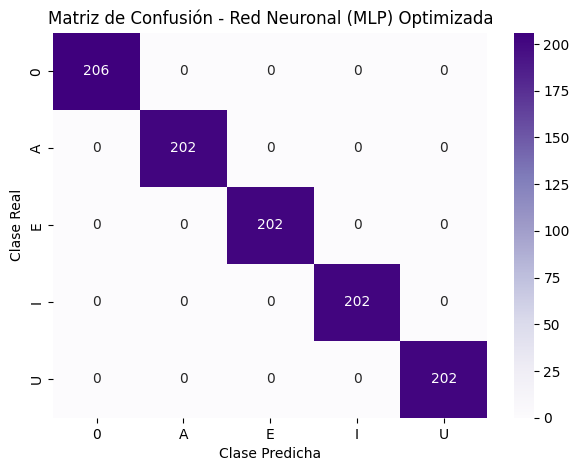

In [ ]:
print("--- Prueba y Evaluación Final (Conjunto de Prueba) ---")
# Predicción sobre el conjunto de prueba aislado (transformado por PCA)
y_pred_mlp = mejor_modelo_mlp.predict(X_test_pca)
acc_test_mlp = accuracy_score(y_test, y_pred_mlp)

print(f"Exactitud en prueba: {acc_test_mlp:.2%}")
print(f"Errores en prueba: {np.count_nonzero(y_test != y_pred_mlp)} de {len(y_test)}")
print(classification_report(
    y_test,
    y_pred_mlp,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
))

# Matriz de Confusión
cm_mlp = confusion_matrix(y_test, y_pred_mlp)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Purples',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Matriz de Confusión - Red Neuronal (MLP) Optimizada")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()

In [ ]:
# Evaluación del modelo sobre el conjunto de entrenamiento
y_pred_mlp_train = mejor_modelo_mlp.predict(X_train_pca)
acc_train_mlp = accuracy_score(y_train, y_pred_mlp_train)

# Diferencia entre entrenamiento y prueba
diferencia_mlp = abs(acc_train_mlp - acc_test_mlp)

print("--- Comprobación de Sobreajuste (MLP) ---")
print(f"Exactitud en entrenamiento: {acc_train_mlp:.2%}")
print(f"Exactitud en prueba: {acc_test_mlp:.2%}")
print(f"Diferencia entre resultados: {diferencia_mlp:.2%}")

--- Comprobación de Sobreajuste (MLP) ---
Exactitud en entrenamiento: 100.00%
Exactitud en prueba: 100.00%
Diferencia entre resultados: 0.00%


## Conclusión y análisis de resultados

La Red Neuronal Multicapa (MLP), después del proceso de optimización de hiperparámetros, alcanzó una exactitud del 100% en el conjunto de prueba, clasificando correctamente la totalidad de las imágenes evaluadas. Adicionalmente, se realizó una comprobación de sobreajuste mediante la comparación de los resultados obtenidos en los conjuntos de entrenamiento y prueba. El modelo alcanzó una exactitud del 100% en ambos conjuntos, con una diferencia de rendimiento del 0%, por lo que no se encontró evidencia de sobreajuste según esta evaluación.

Estos resultados indican que el modelo logró aprender los patrones necesarios para distinguir las cinco clases de vocales manuscritas y mantener su rendimiento sobre datos que no participaron directamente en el entrenamiento. En consecuencia, el MLP presentó un desempeño sobresaliente en la clasificación del conjunto evaluado, demostrando una excelente capacidad de generalización dentro de las condiciones del experimento.

## Guardado del modelo MLP

El perceptrón multicapa se guardó con `joblib` en el archivo `mlp_model.pkl`, dentro del entorno local de Colab. Para clasificar nuevas imágenes se aplica el mismo preprocesamiento y la transformación PCA ajustada durante el entrenamiento antes de entregar los componentes al modelo.

In [ ]:
print("\n--- Persistencia del Modelo ---")
# Guardado del modelo en el directorio de salida
ruta_mlp = RUTA_MODELOS / "mlp_model.pkl"
joblib.dump(mejor_modelo_mlp, ruta_mlp)
print(f"¡Modelo de Red Neuronal guardado exitosamente en: {ruta_mlp.name}!")


--- Persistencia del Modelo ---
¡Modelo de Red Neuronal guardado exitosamente en: mlp_model.pkl!


# Regresión logística multiclase (Softmax)

La regresión logística multiclase estima la probabilidad de que una imagen pertenezca a cada una de las cinco clases y predice la clase con mayor probabilidad. En esta corrida, el modelo recibe 94 componentes principales por imagen.

## Carga de los datos transformados

In [ ]:
print("--- Preparación para Regresión Multivariada (SoftMax) ---")
# --- Carga de los datos transformados mediante PCA ---
# Asegúrate de que la ruta coincide con la que creamos ayer
ruta_datos = RUTA_MODELOS / "datos_transformados_pca.npz"

try:
    # Sobrescribimos las variables en memoria con los datos del Drive
    datos_cargados = np.load(ruta_datos)
    X_train_pca = datos_cargados['X_train_pca']
    X_test_pca = datos_cargados['X_test_pca']
    y_train = datos_cargados['y_train']
    y_test = datos_cargados['y_test']

    print(f"¡Datos PCA cargados exitosamente desde el entorno de Colab!")
    print(f"Dimensiones listas para entrenar -> X_train_pca: {X_train_pca.shape}")
except FileNotFoundError:
    print(f"[ERROR] No se encontró el archivo en {ruta_datos}. Verifica que la etapa de PCA se haya ejecutado correctamente.")

--- Preparación para Regresión Multivariada (SoftMax) ---
¡Datos PCA cargados exitosamente desde el entorno de Colab!
Dimensiones listas para entrenar -> X_train_pca: (4056, 94)


## Configuración de la búsqueda de hiperparámetros

La búsqueda combina cinco valores de `C` (0,01, 0,1, 1, 10 y 100) y dos optimizadores (`lbfgs` y `saga`). Un valor menor de `C` aplica una regularización más fuerte. Las 10 configuraciones se comparan mediante validación cruzada de cinco particiones y se selecciona la de mayor exactitud media.

In [ ]:
print("--- Configuración de la Regresión SoftMax ---")
# Instanciamos el modelo base indicando que es un problema multiclase (multinomial/SoftMax)
# Aumentamos max_iter para asegurar que el algoritmo de optimización converja
softmax_base = LogisticRegression(max_iter=1500, random_state=42)

# Definición de la malla de hiperparámetros
param_grid_softmax = {
    # 'C' es el inverso de la fuerza de regularización (menor valor = mayor regularización)
    'C': [0.01, 0.1, 1, 10, 100],
    # Solvers recomendados para problemas multiclase
    'solver': ['lbfgs', 'saga']
}

# Configuración de GridSearchCV con validación cruzada (cv=5)
grid_search_softmax = GridSearchCV(
    estimator=softmax_base,
    param_grid=param_grid_softmax,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
print("Configuración de hiperparámetros y GridSearchCV lista.")

--- Configuración de la Regresión SoftMax ---
Configuración de hiperparámetros y GridSearchCV lista.


## Entrenamiento de la regresión Softmax

Se ejecutó `GridSearchCV` sobre las 4.056 imágenes de entrenamiento, representadas por 94 componentes principales. Cada una de las 10 configuraciones se evaluó en cinco particiones. La configuración con mayor exactitud media se volvió a entrenar con todo el conjunto de entrenamiento.

In [ ]:
print("--- Iniciando Entrenamiento de la Regresión SoftMax ---")
inicio_softmax = time.time()

# Ajustamos el modelo con los datos de entrenamiento transformados
grid_search_softmax.fit(X_train_pca, y_train)

tiempo_fin_softmax = time.time() - inicio_softmax
mejor_modelo_softmax = grid_search_softmax.best_estimator_

print(f"¡Entrenamiento finalizado en {tiempo_fin_softmax:.2f} segundos!")
print(f"Mejores hiperparámetros encontrados: {grid_search_softmax.best_params_}")
print(f"Mejor precisión en validación cruzada (Train): {grid_search_softmax.best_score_:.4f}")

--- Iniciando Entrenamiento de la Regresión SoftMax ---
Fitting 5 folds for each of 10 candidates, totalling 50 fits
¡Entrenamiento finalizado en 142.08 segundos!
Mejores hiperparámetros encontrados: {'C': 10, 'solver': 'lbfgs'}
Mejor precisión en validación cruzada (Train): 0.9980


## Resultados de la búsqueda de hiperparámetros

In [ ]:
resultados_softmax = pd.DataFrame(grid_search_softmax.cv_results_)

tabla_softmax = (
    resultados_softmax.sort_values("rank_test_score", kind="stable")
    [["param_C", "param_solver", "mean_test_score", "std_test_score"]]
    .rename(columns={
        "param_C": "C",
        "param_solver": "Optimizador",
        "mean_test_score": "Exactitud media",
        "std_test_score": "Desviación estándar",
    })
)

display(tabla_softmax.style.format({
    "Exactitud media": "{:.4%}",
    "Desviación estándar": lambda valor: f"{100 * valor:.3f} pp",
}).hide(axis="index"))

C,Optimizador,Exactitud media,Desviación estándar
10.000000,lbfgs,99.8027%,0.126 pp
100.000000,saga,99.8027%,0.126 pp
10.000000,saga,99.7781%,0.144 pp
1.000000,lbfgs,99.6795%,0.126 pp
1.000000,saga,99.6795%,0.126 pp
100.000000,lbfgs,99.6301%,0.174 pp
0.100000,lbfgs,99.2603%,0.390 pp
0.100000,saga,99.2603%,0.390 pp
0.010000,lbfgs,97.6084%,0.402 pp
0.010000,saga,97.6084%,0.402 pp


### Exactitud de Softmax según la regularización y el optimizador

La gráfica compara la exactitud media en validación cruzada para los cinco valores de `C` y los dos optimizadores. Un valor menor de `C` corresponde a una regularización más fuerte.

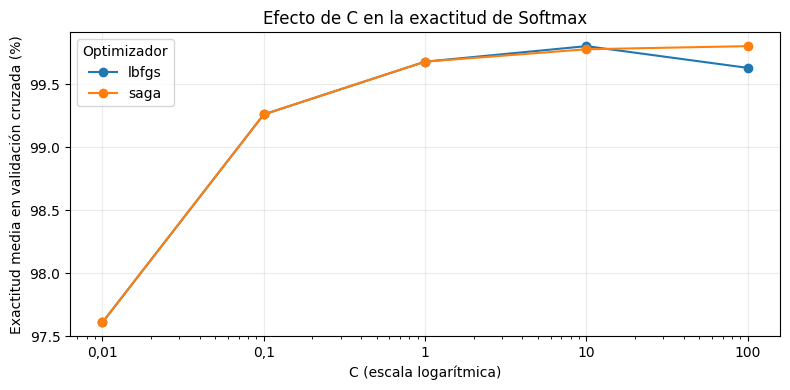

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))

for optimizador, grupo in resultados_softmax.groupby("param_solver"):
    grupo = grupo.sort_values("param_C")
    ax.plot(
        grupo["param_C"],
        grupo["mean_test_score"] * 100,
        marker="o",
        label=optimizador,
    )

ax.set_xscale("log")
ax.set_xticks([0.01, 0.1, 1, 10, 100], ["0,01", "0,1", "1", "10", "100"])
ax.set_xlabel("C (escala logarítmica)")
ax.set_ylabel("Exactitud media en validación cruzada (%)")
ax.set_title("Efecto de C en la exactitud de Softmax")
ax.legend(title="Optimizador")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La búsqueda comparó cinco valores de regularización C con los optimizadores lbfgs y saga. La configuración seleccionada utilizó C = 10 y el optimizador lbfgs, alcanzando una exactitud media del 99,80 % en la validación cruzada de cinco particiones. Este resultado muestra que la mejor combinación proporcionó un equilibrio adecuado entre regularización y ajuste sobre los datos de entrenamiento transformados mediante PCA.

## Evaluación de Softmax en el conjunto de prueba

--- Prueba y Evaluación Final (Conjunto de Prueba) ---
Exactitud en prueba: 99.90%
Errores en prueba: 1 de 1014
              precision    recall  f1-score   support

           0     0.9952    1.0000    0.9976       206
           A     1.0000    1.0000    1.0000       202
           E     1.0000    1.0000    1.0000       202
           I     1.0000    1.0000    1.0000       202
           U     1.0000    0.9950    0.9975       202

    accuracy                         0.9990      1014
   macro avg     0.9990    0.9990    0.9990      1014
weighted avg     0.9990    0.9990    0.9990      1014



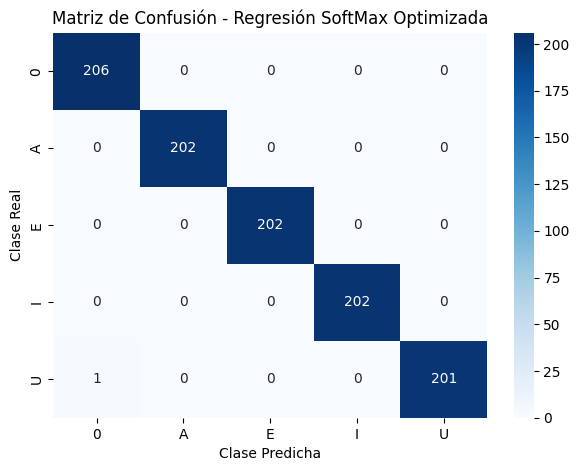

In [ ]:
print("--- Prueba y Evaluación Final (Conjunto de Prueba) ---")
# Predicción sobre el conjunto de prueba aislado
y_pred_softmax = mejor_modelo_softmax.predict(X_test_pca)
acc_test_softmax = accuracy_score(y_test, y_pred_softmax)

print(f"Exactitud en prueba: {acc_test_softmax:.2%}")
print(f"Errores en prueba: {np.count_nonzero(y_test != y_pred_softmax)} de {len(y_test)}")

# Definimos las clases explícitamente basados en el dataset original
nombres_clases = ['0', 'A', 'E', 'I', 'U']

print(classification_report(
    y_test, y_pred_softmax, target_names=nombres_clases, digits=4
))
# Generar y graficar la matriz de confusión
cm_softmax = confusion_matrix(y_test, y_pred_softmax)
plt.figure(figsize=(7, 5))
sns.heatmap(cm_softmax, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases,
            yticklabels=nombres_clases)
plt.title("Matriz de Confusión - Regresión SoftMax Optimizada")
plt.xlabel("Clase Predicha")
plt.ylabel("Clase Real")
plt.show()


## Evaluacion de sobreajuste

In [ ]:
# Evaluación del modelo sobre el conjunto de entrenamiento
y_pred_softmax_train = mejor_modelo_softmax.predict(X_train_pca)
acc_train_softmax = accuracy_score(y_train, y_pred_softmax_train)

# Diferencia entre entrenamiento y prueba
diferencia_softmax = abs(acc_train_softmax - acc_test_softmax)

print("--- Comprobación de Sobreajuste (Softmax) ---")
print(f"Exactitud en entrenamiento: {acc_train_softmax:.2%}")
print(f"Exactitud en prueba: {acc_test_softmax:.2%}")
print(f"Diferencia entre resultados: {diferencia_softmax:.2%}")

--- Comprobación de Sobreajuste (Softmax) ---
Exactitud en entrenamiento: 100.00%
Exactitud en prueba: 99.90%
Diferencia entre resultados: 0.10%


## Guardado del modelo Softmax

In [ ]:
print("\n--- Persistencia del Modelo ---")

ruta_softmax = RUTA_MODELOS / "mejor_modelo_softmax.pkl"
joblib.dump(mejor_modelo_softmax, ruta_softmax)

print(f"¡Modelo de Regresión SoftMax guardado exitosamente en: {ruta_softmax.name}!")


--- Persistencia del Modelo ---
¡Modelo de Regresión SoftMax guardado exitosamente en: mejor_modelo_softmax.pkl!


## Conclusión y análisis de resultados


El modelo de Regresión Softmax optimizado obtuvo una exactitud del **99.90% en el conjunto de prueba**, clasificando correctamente 1.013 de las 1.014 imágenes evaluadas y presentando únicamente un error de clasificación. Los resultados por clase evidencian un desempeño sobresaliente, alcanzando métricas perfectas de precisión y sensibilidad en las vocales A, E e I.

Adicionalmente, se realizó una comprobación de sobreajuste mediante la comparación del rendimiento en los conjuntos de entrenamiento y prueba. El modelo obtuvo una exactitud del **100% en entrenamiento y 99.90% en prueba**, con una diferencia de apenas **0.10 puntos porcentuales**. Esta mínima variación indica que no se encontró evidencia significativa de sobreajuste y que el modelo mantiene un comportamiento consistente frente a datos que no participaron en su entrenamiento.

En conclusión, la Regresión Softmax demostró una excelente capacidad de clasificación y generalización dentro del conjunto de datos evaluado, posicionándose como uno de los modelos con mejor desempeño en el reconocimiento de vocales manuscritas.

# Red neuronal profunda (DNN) con arquitectura convolucional (CNN)

La CNN clasifica cada imagen en una de las cinco clases del proyecto. Recibe imágenes de 32 × 32 píxeles en escala de grises y aplica filtros sobre regiones vecinas para aprender patrones locales, como bordes y trazos. En este modelo se conserva la disposición espacial de los píxeles, por lo que las imágenes se usan directamente sin aplicar PCA.

## Preparación de las imágenes

In [ ]:
X_train_cnn = X_train.reshape(-1, 32, 32, 1).astype("float32")
X_test_cnn = X_test.reshape(-1, 32, 32, 1).astype("float32")

print("Entrenamiento:", X_train_cnn.shape)
print("Prueba:", X_test_cnn.shape)

Entrenamiento: (4056, 32, 32, 1)
Prueba: (1014, 32, 32, 1)


### Comprobación de la correspondencia de los datos

**Comprobación de la partición.** Se reorganizaron las 4.056 imágenes de entrenamiento y las 1.014 de prueba en cuadrículas de 32 × 32 píxeles con un canal. Para verificar que se mantuvieron las mismas imágenes y el mismo orden que en MLP y Softmax, se aplicó el PCA ya ajustado y se compararon los componentes resultantes con los que usaron esos modelos. Ambos conjuntos coincidieron dentro de la tolerancia numérica. La CNN se entrena con las cuadrículas de píxeles.

In [ ]:
for conjunto, imagenes, componentes in [
    ("Entrenamiento", X_train, X_train_pca),
    ("Prueba", X_test, X_test_pca),
]:
    coincide = np.allclose(
        pca.transform(imagenes), componentes, rtol=1e-4, atol=1e-4
    )
    assert coincide, f"Revisar la correspondencia de las imágenes de {conjunto.lower()}."
    print(f"{conjunto}: las imágenes coinciden con los datos transformados.")

Entrenamiento: las imágenes coinciden con los datos transformados.
Prueba: las imágenes coinciden con los datos transformados.


## Configuración de la red neuronal

La red recibe imágenes de 32 × 32 píxeles en escala de grises.
Usamos dos capas convolucionales con filtros de 3 × 3 para aprender
patrones locales, como bordes y curvas, y combinarlos en formas más complejas.
Usamos ReLU para que la red pueda aprender relaciones no lineales.

Después de cada convolución, MaxPooling de 2 × 2 reduce el tamaño
de los mapas de características. Así pasamos de 32 × 32 a 16 × 16
y luego a 8 × 8 antes de la capa densa, lo que reduce la cantidad
de parámetros de esa capa.

La salida tiene cinco neuronas, una por clase. Softmax convierte
sus puntajes en probabilidades. Usamos entropía cruzada para
clasificación multiclase porque cada imagen tiene una sola etiqueta.

La configuración inicial usa 16 filtros en la primera convolución
y 32 en la segunda. En la validación cruzada compararemos esta
configuración con 32 y 64 filtros para ver si aumentar la capacidad
mejora la exactitud. La capa densa de 32 neuronas se mantiene fija
para que la comparación se centre en la cantidad de filtros.

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def construir_cnn(filtros=16):
    modelo = keras.Sequential([
        keras.Input(shape=(32, 32, 1)),
        layers.Conv2D(filtros, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(2 * filtros, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dense(32, activation="relu"),
        layers.Dense(len(label_encoder.classes_), activation="softmax"),
    ])

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )
    return modelo

print("Configuración de la red neuronal lista.")

Configuración de la red neuronal lista.


## Entrenamiento de la red neuronal

Comparamos dos configuraciones de filtros: 16 y 32, y 32 y 64.
Mantenemos fijas 10 épocas y lotes de 32 imágenes para que la
comparación se centre en el número de filtros. Las 10 épocas son
un presupuesto inicial que permite completar la búsqueda con
el mismo tiempo de entrenamiento en términos de pasadas por los datos.

Usamos GridSearchCV con cinco particiones estratificadas. Elegimos
la configuración con mayor exactitud media en validación y luego
la entrenamos con las 4.056 imágenes de entrenamiento. Las 1.014
imágenes de prueba se reservan para la evaluación final.

### Comparación de configuraciones de filtros

In [ ]:
class ClasificadorCNN(ClassifierMixin, BaseEstimator):
    def __init__(self, filtros=16, epochs=10, batch_size=32):
        self.filtros = filtros
        self.epochs = epochs
        self.batch_size = batch_size

    def fit(self, X, y):
        keras.backend.clear_session()
        keras.utils.set_random_seed(42)

        self.classes_, etiquetas = np.unique(y, return_inverse=True)
        self.modelo_ = construir_cnn(filtros=self.filtros)
        self.modelo_.fit(
            X,
            etiquetas,
            epochs=self.epochs,
            batch_size=self.batch_size,
            verbose=0,
        )
        return self

    def predict(self, X):
        probabilidades = self.modelo_.predict(X, verbose=0)
        return self.classes_[probabilidades.argmax(axis=1)]


grid_search_cnn = GridSearchCV(
    estimator=ClasificadorCNN(),
    param_grid={"filtros": [16, 32]},
    cv=StratifiedKFold(n_splits=5),
    scoring="accuracy",
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise",
)

grid_search_cnn.fit(X_train_cnn, y_train)

mejor_modelo_cnn = grid_search_cnn.best_estimator_.modelo_

filtros = grid_search_cnn.best_params_["filtros"]
print(f"Mejor configuración: {filtros} y {2 * filtros} filtros")
print(f"Exactitud media en validación: {grid_search_cnn.best_score_:.2%}")

Fitting 5 folds for each of 2 candidates, totalling 10 fits
[CV] END .........................................filtros=16; total time=  34.2s
[CV] END .........................................filtros=16; total time=  29.0s
[CV] END .........................................filtros=16; total time=  32.5s
[CV] END .........................................filtros=16; total time=  29.5s
[CV] END .........................................filtros=16; total time=  31.3s
[CV] END .........................................filtros=32; total time=  57.8s
[CV] END .........................................filtros=32; total time= 1.0min
[CV] END .........................................filtros=32; total time=  57.5s
[CV] END .........................................filtros=32; total time=  50.6s
[CV] END .........................................filtros=32; total time=  52.7s
Mejor configuración: 32 y 64 filtros
Exactitud media en validación: 99.95%


### Resultados de la comparación de filtros

In [ ]:
resultados_filtros_cnn = pd.DataFrame({
    "Filtros primera capa": [
        p["filtros"] for p in grid_search_cnn.cv_results_["params"]
    ],
    "Filtros segunda capa": [
        2 * p["filtros"] for p in grid_search_cnn.cv_results_["params"]
    ],
    "Exactitud media": grid_search_cnn.cv_results_["mean_test_score"],
    "Desviación estándar (pp)": (
        grid_search_cnn.cv_results_["std_test_score"] * 100
    ),
})

resultados_filtros_cnn = resultados_filtros_cnn.sort_values(
    "Exactitud media",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

display(
    resultados_filtros_cnn.style.format({
        "Exactitud media": "{:.4%}",
        "Desviación estándar (pp)": "{:.3f}",
    })
)

,Filtros primera capa,Filtros segunda capa,Exactitud media,Desviación estándar (pp)
0,32,64,99.9507%,0.060
1,16,32,99.9507%,0.060


### Comparación del número de épocas

In [ ]:
busqueda_cnn_epocas = GridSearchCV(
    estimator=ClasificadorCNN(
    filtros=grid_search_cnn.best_params_["filtros"],
    batch_size=32
),
    param_grid={"epochs": [10, 15, 20]},
    cv=StratifiedKFold(n_splits=5),
    scoring="accuracy",
    refit=False,
    n_jobs=1,
    verbose=1,
    error_score="raise",
)

busqueda_cnn_epocas.fit(X_train_cnn, y_train)

for parametros, media, desviacion in zip(
    busqueda_cnn_epocas.cv_results_["params"],
    busqueda_cnn_epocas.cv_results_["mean_test_score"],
    busqueda_cnn_epocas.cv_results_["std_test_score"],
):
    print(
        f"{parametros['epochs']} épocas: {media:.4%} "
        f"± {desviacion * 100:.3f} puntos porcentuales"
    )

Fitting 5 folds for each of 3 candidates, totalling 15 fits
10 épocas: 99.9507% ± 0.060 puntos porcentuales
15 épocas: 99.9507% ± 0.060 puntos porcentuales
20 épocas: 99.9507% ± 0.060 puntos porcentuales


### Selección de la configuración final

Las configuraciones de 10, 15 y 20 épocas alcanzaron la misma exactitud media de 99,9507 % en las cinco particiones de validación cruzada, con una desviación estándar de 0,060 puntos porcentuales. Como aumentar el número de épocas no produjo una mejora, se seleccionaron 10 épocas siguiendo un criterio de simplicidad y eficiencia computacional.

La configuración final utiliza 32 filtros en la primera capa convolucional, 64 filtros en la segunda, lotes de 32 imágenes, 10 épocas y el optimizador Adam con una tasa de aprendizaje de 0,001. Esta fue la configuración evaluada sobre el conjunto de prueba.

### Resumen de la arquitectura seleccionada

El siguiente resumen muestra las capas de la CNN, las dimensiones de salida y la cantidad de parámetros entrenables. Esto permite observar cómo las convoluciones y las operaciones de agrupamiento reducen progresivamente la representación espacial antes de realizar la clasificación final.

In [ ]:
mejor_modelo_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       131,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 450,257 (1.72 MB)

 Trainable params: 150,085 (586.27 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 300,172 (1.15 MB)

## Evaluación de la CNN en el conjunto de prueba

Evaluamos la CNN seleccionada sobre el mismo conjunto de prueba que
los demás métodos. Calculamos la exactitud, el F1 macro y el número
de errores. La matriz de confusión muestra qué clases confundió la red.

Exactitud en prueba: 100.00%
F1 macro: 100.00%
Errores: 0 de 1014

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       206
           A     1.0000    1.0000    1.0000       202
           E     1.0000    1.0000    1.0000       202
           I     1.0000    1.0000    1.0000       202
           U     1.0000    1.0000    1.0000       202

    accuracy                         1.0000      1014
   macro avg     1.0000    1.0000    1.0000      1014
weighted avg     1.0000    1.0000    1.0000      1014



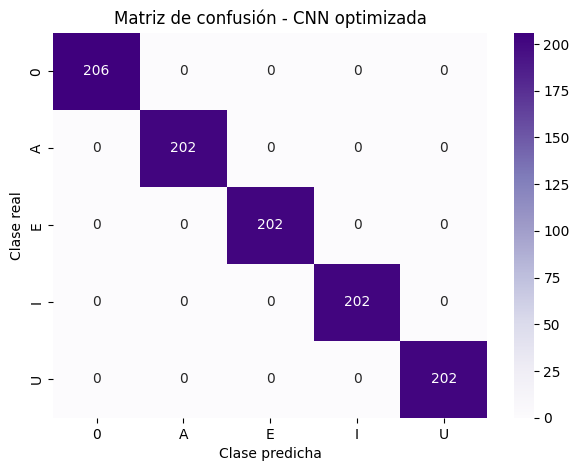

In [ ]:
from sklearn.metrics import f1_score

y_pred_cnn = grid_search_cnn.predict(X_test_cnn)
clases_cnn = label_encoder.classes_
etiquetas_cnn = np.arange(len(clases_cnn))

acc_test_cnn = accuracy_score(y_test, y_pred_cnn)
f1_macro_cnn = f1_score(y_test, y_pred_cnn, average="macro")
errores_cnn = np.count_nonzero(y_test != y_pred_cnn)

print(f"Exactitud en prueba: {acc_test_cnn:.2%}")
print(f"F1 macro: {f1_macro_cnn:.2%}")
print(f"Errores: {errores_cnn} de {len(y_test)}")
print()
print(classification_report(
    y_test, y_pred_cnn, labels=etiquetas_cnn, target_names=clases_cnn,
    digits=4, zero_division=0,
))

cm_cnn = confusion_matrix(y_test, y_pred_cnn, labels=etiquetas_cnn)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_cnn, annot=True, fmt="d", cmap="Purples",
    xticklabels=clases_cnn, yticklabels=clases_cnn,
)
plt.title("Matriz de confusión - CNN optimizada")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.show()

## Conclusión y análisis de resultados

**Selección de la arquitectura.** La CNN recibió imágenes de 32 × 32 píxeles en escala de grises, conservando su disposición espacial. Mediante validación cruzada estratificada de cinco particiones se compararon dos arquitecturas: una con 16 y 32 filtros, y otra con 32 y 64 filtros. GridSearchCV seleccionó la arquitectura de 32 y 64 filtros, que alcanzó una exactitud media aproximada del 99,95 % en validación cruzada.

**Selección del número de épocas.** Con la arquitectura seleccionada de 32 y 64 filtros se compararon entrenamientos de 10, 15 y 20 épocas. Las tres alternativas obtuvieron una exactitud media de 99,9507 % y una desviación estándar de 0,060 puntos porcentuales. Debido a que aumentar el número de épocas no produjo una mejora, se seleccionaron 10 épocas por su menor costo computacional.

**Rendimiento en el conjunto de prueba.** La configuración final clasificó correctamente las 1.014 imágenes del conjunto de prueba, alcanzando una exactitud del 100 % y un F1 macro del 100 %, sin errores de clasificación. Todas las imágenes de las clases 0, A, E, I y U fueron reconocidas correctamente en esta partición.

**Interpretación del resultado.** La CNN obtuvo resultados prácticamente perfectos tanto en validación cruzada como en el conjunto de prueba. Esto muestra que aprendió consistentemente los patrones espaciales presentes en las imágenes mediante sus capas convolucionales. Sin embargo, el 100 % alcanzado en esta partición no garantiza el mismo desempeño con imágenes externas, otros autores, diferentes estilos de escritura o condiciones de captura menos controladas.

## Guardado del modelo CNN

La arquitectura y los pesos de la CNN seleccionada se guardan en formato `.keras`. Este archivo permite recuperar el modelo para realizar nuevas predicciones sin repetir la búsqueda de hiperparámetros ni el entrenamiento.

In [ ]:
print("\n--- Guardado del modelo CNN ---")

ruta_cnn = RUTA_MODELOS / "cnn_model.keras"
mejor_modelo_cnn.save(ruta_cnn)

print(f"Modelo CNN guardado correctamente en: {ruta_cnn.name}")


--- Guardado del modelo CNN ---
Modelo CNN guardado correctamente en: cnn_model.keras


# Comparación final de los modelos

## Recuperación de modelos y datos para la comparación final

Con el propósito de realizar una comparación conjunta de los cinco modelos sin ejecutar nuevamente sus respectivos procesos de entrenamiento, se optó por guardar cada modelo una vez finalizado su desarrollo. De igual manera, se almacenaron los datos transformados mediante PCA y el dataset redimensionado a 32×32 píxeles.

De esta manera, es posible cargar posteriormente los modelos y los conjuntos de datos previamente almacenados para realizar las predicciones y evaluaciones sobre las mismas particiones de entrenamiento y prueba. Esto permite centralizar los resultados, facilitar su comparación y evitar repetir procesos computacionalmente costosos, como el entrenamiento de la red neuronal convolucional.

In [ ]:

# ==========================================
#  CARGAR DATOS
# ==========================================

datos_pca = np.load(RUTA_MODELOS / "datos_transformados_pca.npz")

X_train_pca = datos_pca["X_train_pca"]
X_test_pca = datos_pca["X_test_pca"]
y_test_pca = datos_pca["y_test"]

datos_originales = np.load(
    RUTA_SALIDAS / "DATASET_PROCESADO_32x32.npz"
)

X = datos_originales["X"]
y = datos_originales["y"]

# Codificar etiquetas originales
label_encoder = LabelEncoder()
y_codificado = label_encoder.fit_transform(y)

# Recuperar exactamente la partición original
indices = np.arange(len(X))

indices_train, indices_test = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_codificado
)

X_test_original = X[indices_test]
y_test_original = y_codificado[indices_test]

# Verificar que las etiquetas coincidan con las del archivo PCA
if not np.array_equal(y_test_original, y_test_pca):
    raise ValueError(
        "Las etiquetas originales no coinciden con las del conjunto PCA. "
        "Verifica la partición original del dataset."
    )

# Preparar imágenes para CNN
X_test_cnn = X_test_original[..., np.newaxis]

# ==========================================
# CARGAR MODELOS
# ==========================================

modelo_rf = joblib.load(
    RUTA_MODELOS / "random_forest_model.pkl"
)

modelo_dt = joblib.load(
    RUTA_MODELOS / "decision_tree_model.pkl"
)

modelo_mlp = joblib.load(
    RUTA_MODELOS / "mlp_model.pkl"
)

modelo_softmax = joblib.load(
    RUTA_MODELOS / "mejor_modelo_softmax.pkl"
)

modelo_cnn = load_model(
    RUTA_MODELOS / "cnn_model.keras"
)

# ==========================================
#  GENERAR PREDICCIONES
# ==========================================

# Random Forest:
pred_rf = modelo_rf.predict(X_test_pca)

# Árbol de decisión
pred_dt = modelo_dt.predict(X_test_pca)

# MLP
pred_mlp = modelo_mlp.predict(X_test_pca)

# Softmax
pred_softmax = modelo_softmax.predict(X_test_pca)

# CNN
salidas_cnn = modelo_cnn.predict(
    X_test_cnn,
    verbose=0
)

pred_cnn = np.argmax(salidas_cnn, axis=1)

# ==========================================
# 5. COMPARACIÓN FINAL
# ==========================================

predicciones = {
    "Random Forest": pred_rf,
    "Árbol de decisión": pred_dt,
    "Perceptrón multicapa (MLP)": pred_mlp,
    "Regresión logística multiclase (Softmax)": pred_softmax,
    "Red neuronal convolucional (CNN)": pred_cnn,
}

etiquetas_prueba = np.asarray(y_test_pca).ravel()
resultados_finales = []

for nombre, prediccion in predicciones.items():

    etiquetas_predichas = np.asarray(prediccion).ravel()

    if len(etiquetas_predichas) != len(etiquetas_prueba):
        raise ValueError(
            f"{nombre} no contiene el mismo número de predicciones que y_test."
        )

    resultados_finales.append({
        "Modelo": nombre,
        "Exactitud": accuracy_score(
            etiquetas_prueba,
            etiquetas_predichas
        ),
        "F1 macro": f1_score(
            etiquetas_prueba,
            etiquetas_predichas,
            average="macro",
            zero_division=0
        ),
        "Errores": np.count_nonzero(
            etiquetas_prueba != etiquetas_predichas
        )
    })

tabla_comparacion_final = (
    pd.DataFrame(resultados_finales)
    .sort_values(
        ["Exactitud", "F1 macro"],
        ascending=False,
        kind="stable"
    )
    .reset_index(drop=True)
)

print("=== COMPARACIÓN FINAL DE MODELOS ===")

display(
    tabla_comparacion_final.style.format({
        "Exactitud": "{:.2%}",
        "F1 macro": "{:.2%}"
    }).hide(axis="index")
)


=== COMPARACIÓN FINAL DE MODELOS ===


Modelo,Exactitud,F1 macro,Errores
Perceptrón multicapa (MLP),100.00%,100.00%,0
Red neuronal convolucional (CNN),100.00%,100.00%,0
Regresión logística multiclase (Softmax),99.90%,99.90%,1
Random Forest,99.01%,99.02%,10
Árbol de decisión,95.36%,95.37%,47


## Comparación de métricas en el conjunto de prueba

Se comparan la exactitud, la precisión macro, la sensibilidad macro y el F1 macro de los cinco modelos sobre las mismas 1.014 imágenes del conjunto de prueba. Las métricas macro asignan la misma importancia a cada una de las cinco clases, independientemente de la cantidad de imágenes que contiene cada una, permitiendo evaluar el rendimiento de los modelos sin favorecer una clase en particular.

El eje vertical de la gráfica se amplía desde el 94% para facilitar la visualización de las pequeñas diferencias de rendimiento entre los modelos.

Modelo,Exactitud,Precisión macro,Sensibilidad macro,F1 macro
Perceptrón multicapa (MLP),100.00%,100.00%,100.00%,100.00%
Red neuronal convolucional (CNN),100.00%,100.00%,100.00%,100.00%
Regresión logística multiclase (Softmax),99.90%,99.90%,99.90%,99.90%
Random Forest,99.01%,99.02%,99.02%,99.02%
Árbol de decisión,95.36%,95.41%,95.37%,95.37%


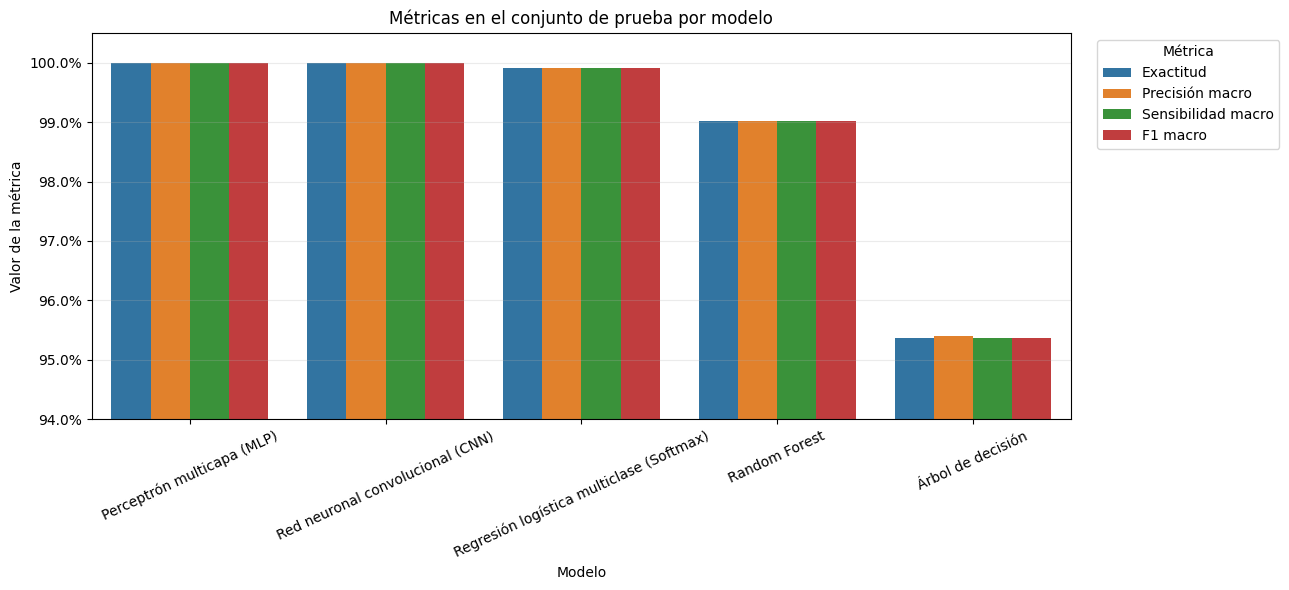

In [ ]:
filas_metricas = []

for modelo, prediccion in predicciones.items():
    y_pred = np.asarray(prediccion).ravel()

    filas_metricas.append({
        "Modelo": modelo,
        "Exactitud": accuracy_score(etiquetas_prueba, y_pred),
        "Precisión macro": precision_score(
            etiquetas_prueba, y_pred,
            average="macro",
            zero_division=0,
        ),
        "Sensibilidad macro": recall_score(
            etiquetas_prueba, y_pred,
            average="macro",
            zero_division=0,
        ),
        "F1 macro": f1_score(
            etiquetas_prueba, y_pred,
            average="macro",
            zero_division=0,
        ),
    })

tabla_metricas_final = pd.DataFrame(filas_metricas)
tabla_metricas_final = (
    tabla_metricas_final
    .set_index("Modelo")
    .loc[tabla_comparacion_final["Modelo"]]
    .reset_index()
)

display(
    tabla_metricas_final.style.format({
        "Exactitud": "{:.2%}",
        "Precisión macro": "{:.2%}",
        "Sensibilidad macro": "{:.2%}",
        "F1 macro": "{:.2%}",
    }).hide(axis="index")
)

metricas_largas = tabla_metricas_final.melt(
    id_vars="Modelo",
    var_name="Métrica",
    value_name="Valor",
)

orden_modelos = tabla_comparacion_final["Modelo"].tolist()

fig, ax = plt.subplots(figsize=(13, 6))

sns.barplot(
    data=metricas_largas,
    x="Modelo",
    y="Valor",
    hue="Métrica",
    order=orden_modelos,
    ax=ax,
)

ax.set_title("Métricas en el conjunto de prueba por modelo")
ax.set_xlabel("Modelo")
ax.set_ylabel("Valor de la métrica")
ax.set_ylim(0.94, 1.005)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Métrica", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

Los resultados de la evaluación final muestran que el Perceptrón Multicapa (MLP) y la Red Neuronal Convolucional (CNN) obtuvieron el mejor desempeño, alcanzando un 100% en exactitud, precisión macro, sensibilidad macro y F1 macro. Ambos modelos clasificaron correctamente la totalidad de las imágenes del conjunto de prueba, demostrando un rendimiento sobresaliente en las cinco clases evaluadas.

Por su parte, la regresión Softmax obtuvo una exactitud y un F1 macro de 99,90 %. Random Forest alcanzó una exactitud de 99,01 % y un F1 macro de 99,02 %. Finalmente, el árbol de decisión obtuvo una exactitud de 95,36 % y un F1 macro de 95,37 %, siendo el modelo con menor desempeño comparativo.

En general, los resultados evidencian que los cinco modelos consiguieron un alto nivel de reconocimiento de vocales manuscritas, destacándose especialmente el MLP y la CNN, que alcanzaron resultados perfectos en las métricas analizadas mediante dos enfoques de aprendizaje diferentes.

## Comparación de la exactitud en entrenamiento y prueba

Esta gráfica permite analizar la capacidad de generalización de los modelos. Una diferencia considerable entre la exactitud de entrenamiento y la de prueba puede indicar sobreajuste. Todos los modelos se comparan utilizando la misma partición previamente definida.

Modelo,Entrenamiento,Prueba
Perceptrón multicapa (MLP),100.00%,100.00%
Red neuronal convolucional (CNN),100.00%,100.00%
Regresión logística multiclase (Softmax),100.00%,99.90%
Random Forest,99.46%,99.01%
Árbol de decisión,99.75%,95.36%


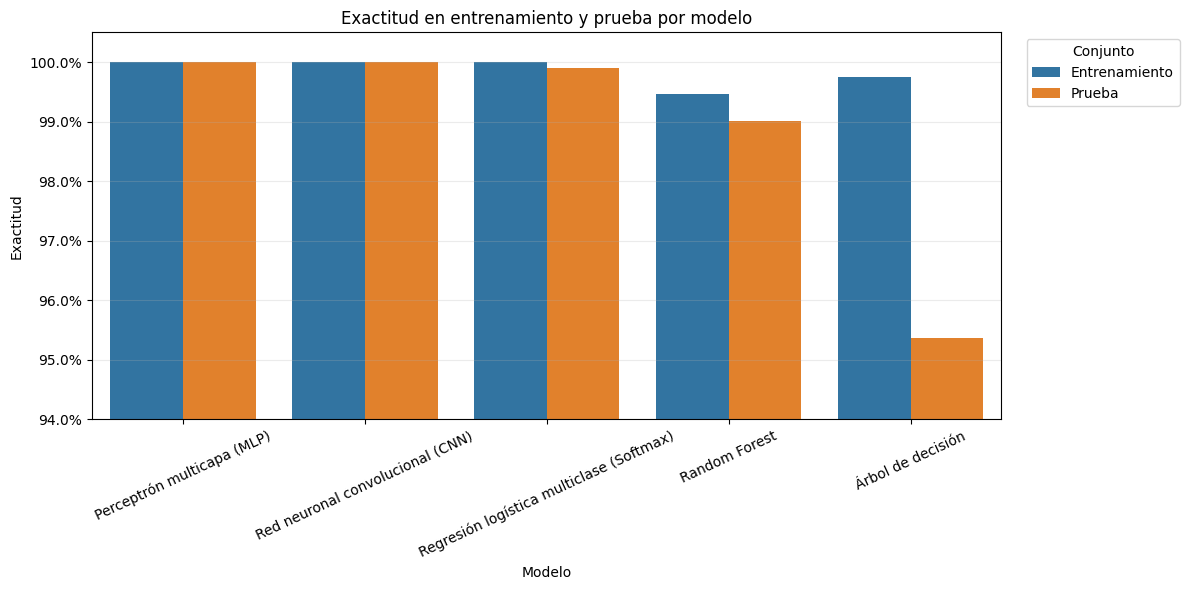

In [ ]:

# ==========================================
# COMPARACIÓN DE EXACTITUD EN ENTRENAMIENTO Y PRUEBA
# ==========================================

# Recuperar datos originales de entrenamiento
X_train_original = X[indices_train]
X_train_cnn = X_train_original[..., np.newaxis]
y_train_pca = datos_pca["y_train"]
y_test_pca = datos_pca["y_test"]
# ==========================================
# 1. PREDICCIONES EN ENTRENAMIENTO
# ==========================================

# Random Forest
predicciones_entrenamiento = {
    "Random Forest": modelo_rf.predict(X_train_pca),

    "Árbol de decisión": modelo_dt.predict(X_train_pca),

    "Perceptrón multicapa (MLP)": modelo_mlp.predict(X_train_pca),

    "Regresión logística multiclase (Softmax)": modelo_softmax.predict(
        X_train_pca
    ),

    "Red neuronal convolucional (CNN)": np.argmax(
        modelo_cnn.predict(X_train_cnn, verbose=0),
        axis=1
    ),
}

# ==========================================
# 2. CALCULAR EXACTITUD
# ==========================================

exactitud_entrenamiento = {
    modelo: accuracy_score(y_train_pca, prediccion)
    for modelo, prediccion in predicciones_entrenamiento.items()
}

exactitud_prueba = dict(zip(
    tabla_comparacion_final["Modelo"],
    tabla_comparacion_final["Exactitud"]
))

# ==========================================
# 3. CONSTRUIR TABLA
# ==========================================

tabla_train_test = pd.DataFrame({
    "Modelo": tabla_comparacion_final["Modelo"],
    "Entrenamiento": [
        exactitud_entrenamiento[modelo]
        for modelo in tabla_comparacion_final["Modelo"]
    ],
    "Prueba": [
        exactitud_prueba[modelo]
        for modelo in tabla_comparacion_final["Modelo"]
    ],
})

display(
    tabla_train_test.style.format({
        "Entrenamiento": "{:.2%}",
        "Prueba": "{:.2%}",
    }).hide(axis="index")
)

# ==========================================
# 4. GRAFICAR RESULTADOS
# ==========================================

comparacion_train_test = tabla_train_test.melt(
    id_vars="Modelo",
    var_name="Conjunto",
    value_name="Exactitud",
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=comparacion_train_test,
    x="Modelo",
    y="Exactitud",
    hue="Conjunto",
    ax=ax,
)

ax.set_title("Exactitud en entrenamiento y prueba por modelo")
ax.set_xlabel("Modelo")
ax.set_ylabel("Exactitud")
ax.set_ylim(0.94, 1.005)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)

ax.legend(
    title="Conjunto",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


## Comparación del número de errores

Debido a que varios modelos alcanzaron exactitudes cercanas al 100 %, se compara también el número absoluto de clasificaciones incorrectas sobre las 1.014 imágenes de prueba. Esta representación permite observar con mayor claridad diferencias que parecen pequeñas cuando se expresan solamente mediante porcentajes.

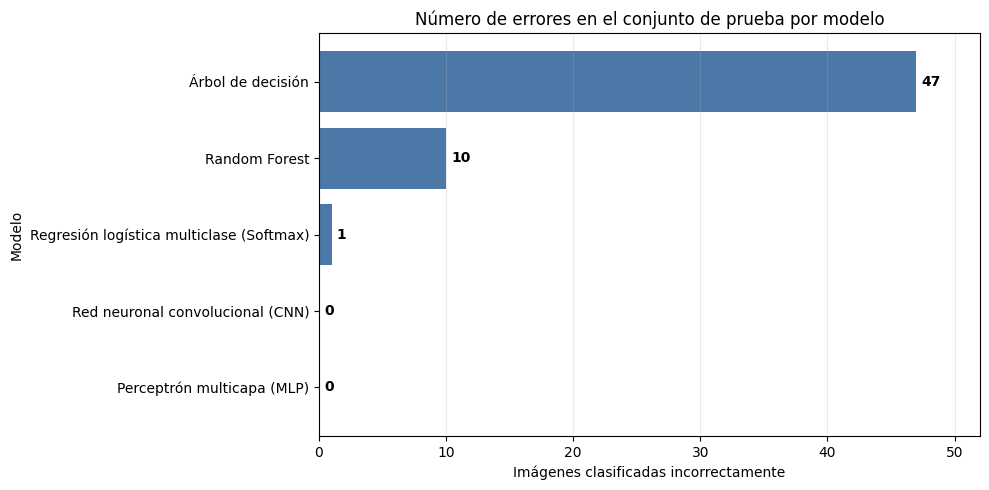

In [ ]:
tabla_errores = (
    tabla_comparacion_final
    .sort_values("Errores", ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.barh(
    tabla_errores["Modelo"],
    tabla_errores["Errores"],
    color="#4C78A8",
)

for barra, errores in zip(barras, tabla_errores["Errores"]):
    ax.text(
        errores + 0.4,
        barra.get_y() + barra.get_height() / 2,
        str(errores),
        va="center",
        fontweight="bold",
    )

ax.set_title("Número de errores en el conjunto de prueba por modelo")
ax.set_xlabel("Imágenes clasificadas incorrectamente")
ax.set_ylabel("Modelo")
ax.set_xlim(0, tabla_errores["Errores"].max() + 5)
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## Consideraciones sobre el Árbol de Decisión y la metodología de comparación

El **Árbol de Decisión** presentó el menor desempeño entre los modelos evaluados, con una exactitud del 95.36% y 47 errores en el conjunto de prueba. Una posible explicación de este resultado se relaciona con las características de su arquitectura: al construir decisiones mediante divisiones sucesivas de las características, un árbol individual puede tener dificultades para representar la variedad de formas, trazos y variaciones presentes en la escritura manuscrita. Además, su capacidad de generalización puede verse limitada cuando aprende reglas demasiado específicas a partir de los datos de entrenamiento.

Todos los modelos finales corresponden a las configuraciones seleccionadas mediante validación cruzada. En Random Forest, árbol de decisión, MLP, Softmax y la búsqueda de filtros de la CNN, GridSearchCV reajustó automáticamente la mejor configuración utilizando todo el conjunto de entrenamiento. En la comparación del número de épocas de la CNN, las tres alternativas obtuvieron el mismo resultado medio, por lo que se conservaron 10 épocas por eficiencia computacional. Posteriormente, todos los modelos se evaluaron sobre el mismo conjunto de prueba, sin utilizarlo para seleccionar hiperparámetros.


## Conclusión de la comparación

### Sobre el desempeño de los modelos

El objetivo central de este proyecto consistió en desarrollar y comparar cinco modelos de aprendizaje supervisado capaces de clasificar imágenes de las cinco vocales manuscritas, considerando las variaciones morfológicas propias de la escritura humana. Todos los modelos fueron evaluados sobre el mismo conjunto de prueba aislado, compuesto por 1.014 imágenes, permitiendo realizar una comparación directa de su capacidad de clasificación.

Los resultados obtenidos demuestran la eficacia de los modelos de aprendizaje automático para resolver esta tarea de reconocimiento óptico de caracteres (OCR):

- **Perceptrón Multicapa (MLP):** obtuvo una exactitud del **100% en el conjunto de prueba**, sin presentar clasificaciones incorrectas. Este resultado evidencia su capacidad para aprender patrones complejos a partir de las características transformadas mediante PCA.

- **Red Neuronal Convolucional (CNN):** también alcanzó una exactitud del **100%**, con cero errores de clasificación. Su arquitectura permitió aprender características espaciales de las imágenes, como trazos, bordes y patrones visuales, trabajando directamente con las imágenes de 32×32 píxeles.

- **Regresión Logística Multiclase (Softmax):** consiguió una exactitud del **99.90%**, con un único error de clasificación. Su rendimiento demuestra que un modelo lineal puede obtener resultados altamente competitivos cuando trabaja con características adecuadamente procesadas mediante PCA.

- **Random Forest:** alcanzó una exactitud del **99.01%**, con 10 errores de clasificación. El uso de múltiples árboles de decisión permitió obtener un rendimiento elevado y una buena capacidad de clasificación sobre las imágenes de prueba.

- **Árbol de Decisión:** obtuvo una exactitud del **95.36%**, con 47 errores de clasificación. Aunque consiguió resultados satisfactorios, presentó el menor rendimiento de los cinco modelos, mostrando mayores dificultades para reconocer algunas variaciones en los trazos de las vocales.


## Comparación de tiempos de predicción
Se evaluó el tiempo requerido por cada modelo para realizar la clasificación de las 1.014 imágenes pertenecientes al conjunto de prueba. Para ello, se utilizaron los modelos previamente entrenados y almacenados, evitando repetir sus respectivos procesos de entrenamiento.

Los tiempos obtenidos tienen un propósito informativo y permiten conocer el costo temporal aproximado de la etapa de predicción. Estos valores pueden variar dependiendo del hardware, los recursos disponibles y las condiciones del entorno de ejecución, por lo que no se consideran un criterio para determinar la superioridad de un modelo.

### Consideraciones metodológicas

Para mantener condiciones de medición homogéneas, se establecieron los siguientes criterios:

Cargar los cinco modelos antes de iniciar las mediciones.

Preparar los datos requeridos por cada arquitectura.

Medir exclusivamente el tiempo de predicción, sin incluir la carga de los modelos ni el preprocesamiento.

Realizar cinco mediciones por modelo y calcular su tiempo promedio.

Representar los resultados mediante una gráfica, utilizando segundos como unidad de medida.

El código incluye las importaciones, la recuperación de los datos y la carga de los modelos necesarios, permitiendo ejecutar la comparación de tiempos sin repetir los procesos de entrenamiento, siempre que los archivos requeridos estén disponibles en el entorno de ejecución.

=== DATOS DE EVALUACIÓN ===
Imágenes de prueba: 1014
Datos PCA: (1014, 94)
Datos CNN: (1014, 32, 32, 1)

=== PREPARANDO MODELOS ===
Random Forest - preparado
Árbol de decisión - preparado
Perceptrón multicapa (MLP) - preparado
Regresión logística multiclase (Softmax) - preparado
Red neuronal convolucional (CNN) - preparado

=== MIDIENDO TIEMPOS DE PREDICCIÓN ===
Random Forest: 0.0325 segundos de promedio
Árbol de decisión: 0.0005 segundos de promedio
Perceptrón multicapa (MLP): 0.0029 segundos de promedio
Regresión logística multiclase (Softmax): 0.0008 segundos de promedio
Red neuronal convolucional (CNN): 0.7223 segundos de promedio

=== RESULTADOS DE TIEMPOS DE PREDICCIÓN ===


Modelo,Tiempo promedio (s),Tiempo promedio (min),Tiempo por imagen (ms)
Árbol de decisión,0.0005,0.000009,0.0005
Regresión logística multiclase (Softmax),0.0008,0.000013,0.0008
Perceptrón multicapa (MLP),0.0029,0.000048,0.0029
Random Forest,0.0325,0.000542,0.0321
Red neuronal convolucional (CNN),0.7223,0.012039,0.7123


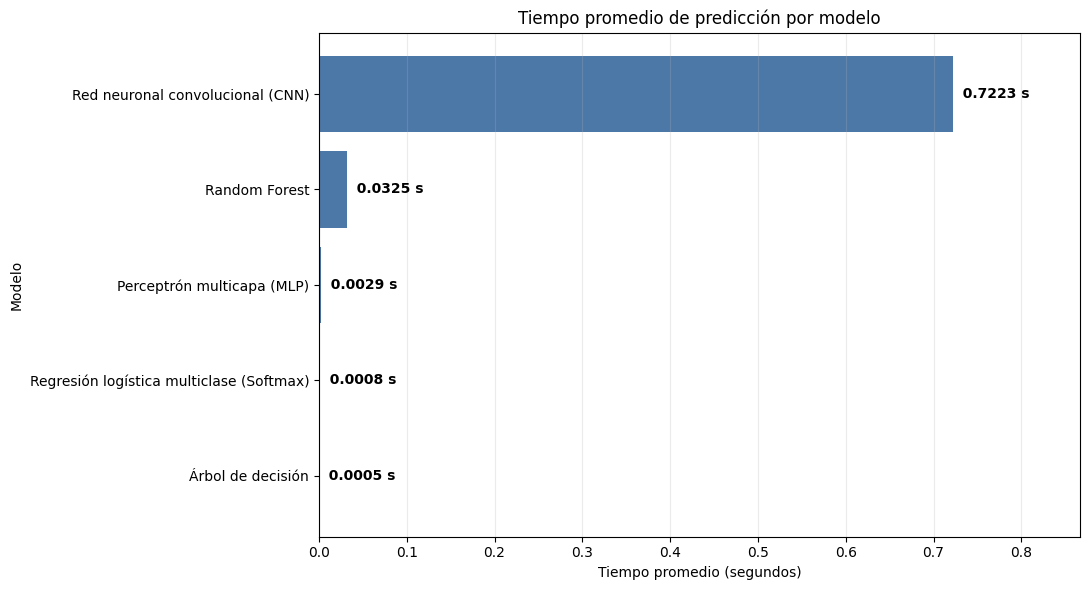

In [ ]:

# ==========================================
# COMPARACIÓN DE TIEMPOS DE PREDICCIÓN
# ==========================================

from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import load_model


# ==========================================
# 1. CARGAR DATASETS
# ==========================================

RUTA_TRABAJO = Path("/content/ocr_vocales")
RUTA_SALIDAS = RUTA_TRABAJO / "salidas"
RUTA_MODELOS = RUTA_SALIDAS / "MODELS"

RUTA_NPZ_32 = RUTA_SALIDAS / "DATASET_PROCESADO_32x32.npz"

# Dataset original
with np.load(RUTA_NPZ_32) as datos:
    X = datos["X"]
    y = datos["y"]

# Datos transformados mediante PCA
with np.load(RUTA_MODELOS / "datos_transformados_pca.npz") as datos_pca:
    X_test_pca = datos_pca["X_test_pca"]
    y_test_pca = datos_pca["y_test"]


# ==========================================
# 2. RECONSTRUIR CONJUNTO DE PRUEBA
# ==========================================

codificador = LabelEncoder()
y_codificado = codificador.fit_transform(y)

indices_train, indices_test = train_test_split(
    np.arange(len(X)),
    test_size=0.20,
    random_state=42,
    stratify=y_codificado
)

# Verificar que se conserva la partición original
if not np.array_equal(y_codificado[indices_test], y_test_pca):
    raise ValueError(
        "Las etiquetas reconstruidas no coinciden con las del archivo PCA."
    )

# Preparar imágenes para CNN
X_test_cnn = X[indices_test][..., np.newaxis]

print("=== DATOS DE EVALUACIÓN ===")
print("Imágenes de prueba:", len(indices_test))
print("Datos PCA:", X_test_pca.shape)
print("Datos CNN:", X_test_cnn.shape)


# ==========================================
# 3. CARGAR MODELOS GUARDADOS
# ==========================================

modelo_rf = joblib.load(
    RUTA_MODELOS / "random_forest_model.pkl"
)

modelo_dt = joblib.load(
    RUTA_MODELOS / "decision_tree_model.pkl"
)

modelo_mlp = joblib.load(
    RUTA_MODELOS / "mlp_model.pkl"
)

modelo_softmax = joblib.load(
    RUTA_MODELOS / "mejor_modelo_softmax.pkl"
)

modelo_cnn = load_model(
    RUTA_MODELOS / "cnn_model.keras"
)


# ==========================================
# 4. DEFINIR PREDICCIONES
# ==========================================

funciones_prediccion = {
    "Random Forest": lambda: modelo_rf.predict(X_test_pca),

    "Árbol de decisión": lambda: modelo_dt.predict(X_test_pca),

    "Perceptrón multicapa (MLP)": lambda: modelo_mlp.predict(X_test_pca),

    "Regresión logística multiclase (Softmax)": lambda: modelo_softmax.predict(
        X_test_pca
    ),

    "Red neuronal convolucional (CNN)": lambda: np.argmax(
        modelo_cnn.predict(X_test_cnn, verbose=0),
        axis=1
    )
}


# ==========================================
# 5. CALENTAMIENTO DE LOS MODELOS
# ==========================================

# Primera predicción fuera de la medición.
# Permite evitar parte del costo de inicialización.

print("\n=== PREPARANDO MODELOS ===")

for nombre, funcion in funciones_prediccion.items():
    funcion()
    print(nombre, "- preparado")


# ==========================================
# 6. MEDIR TIEMPOS DE PREDICCIÓN
# ==========================================

REPETICIONES = 5

tiempos_prediccion = {}

print("\n=== MIDIENDO TIEMPOS DE PREDICCIÓN ===")

for nombre, funcion in funciones_prediccion.items():

    tiempos = []

    for repeticion in range(REPETICIONES):

        inicio = time.perf_counter()

        prediccion = funcion()

        fin = time.perf_counter()

        tiempos.append(fin - inicio)

    tiempos_prediccion[nombre] = tiempos

    print(
        f"{nombre}: "
        f"{np.mean(tiempos):.4f} segundos de promedio"
    )


# ==========================================
# 7. CONSTRUIR TABLA DE RESULTADOS
# ==========================================

resultados_tiempos = []

for nombre, tiempos in tiempos_prediccion.items():

    tiempo_promedio = np.mean(tiempos)

    resultados_tiempos.append({
        "Modelo": nombre,
        "Tiempo promedio (s)": tiempo_promedio,
        "Tiempo promedio (min)": tiempo_promedio / 60,
        "Tiempo por imagen (ms)": (
            tiempo_promedio / len(X_test_pca)
        ) * 1000
    })

tabla_tiempos = pd.DataFrame(resultados_tiempos)

tabla_tiempos = tabla_tiempos.sort_values(
    "Tiempo promedio (s)",
    ascending=True
).reset_index(drop=True)

print("\n=== RESULTADOS DE TIEMPOS DE PREDICCIÓN ===")

display(
    tabla_tiempos.style.format({
        "Tiempo promedio (s)": "{:.4f}",
        "Tiempo promedio (min)": "{:.6f}",
        "Tiempo por imagen (ms)": "{:.4f}"
    }).hide(axis="index")
)


# ==========================================
# 8. GRAFICAR RESULTADOS
# ==========================================

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    tabla_tiempos["Modelo"],
    tabla_tiempos["Tiempo promedio (s)"],
    color="#4C78A8"
)

for barra, tiempo in zip(
    barras,
    tabla_tiempos["Tiempo promedio (s)"]
):
    ax.text(
        tiempo,
        barra.get_y() + barra.get_height() / 2,
        f"  {tiempo:.4f} s",
        va="center",
        fontweight="bold"
    )

ax.set_title("Tiempo promedio de predicción por modelo")
ax.set_xlabel("Tiempo promedio (segundos)")
ax.set_ylabel("Modelo")

ax.set_xlim(
    0,
    tabla_tiempos["Tiempo promedio (s)"].max() * 1.20
)

ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


Los tiempos presentados deben interpretarse como referencias aproximadas del costo temporal de predicción y no como valores absolutos o definitivos del rendimiento computacional. Aunque las mediciones se realizaron bajo las mismas condiciones de ejecución, pueden existir variaciones asociadas a los recursos de hardware y al entorno utilizado.

Esta prueba tiene un carácter exclusivamente informativo y complementario a la evaluación de los modelos. Por tanto, no se establecen conclusiones sobre la superioridad de una arquitectura basándose en su velocidad de predicción, ya que el objetivo principal del proyecto es evaluar su capacidad para clasificar correctamente las vocales manuscritas.


## Conclusión general

En términos generales, los resultados posicionan al **MLP y a la CNN como los modelos con mejor desempeño**, ambos con una exactitud del 100% y sin errores en el conjunto de prueba. No obstante, sus enfoques son diferentes: el MLP trabaja con características reducidas mediante PCA, mientras que la CNN aprende directamente de la estructura espacial de las imágenes.

Por otra parte, Softmax y Random Forest también demostraron un rendimiento elevado, con exactitudes superiores al 99%. El Árbol de Decisión obtuvo el resultado más bajo en comparación con los demás modelos.

Finalmente, el análisis conjunto de las métricas de evaluación, el número de errores y la comparación entre entrenamiento y prueba permitió identificar las fortalezas y diferencias de cada arquitectura. Estos resultados muestran que tanto las técnicas tradicionales de aprendizaje automático como las redes neuronales pueden ser eficaces para la clasificación de vocales manuscritas, aunque su rendimiento depende de la arquitectura y del procesamiento de los datos.

**°_Nota de reproducibilidad. Los valores presentados corresponden a la ejecución guardada en este notebook. Debido a componentes estocásticos del entrenamiento, una nueva ejecución podría producir variaciones menores, especialmente en los modelos neuronales, sin que se espere un cambio sustancial en las conclusiones generales_.**

# Lecciones aprendidas
Una de las principales lecciones aprendidas fue la importancia de comprender correctamente el problema antes de comenzar a desarrollar los modelos. Fue necesario identificar qué se buscaba resolver, conocer las características de las vocales manuscritas y entender las condiciones del conjunto de datos. Asimismo, se reconoció que el trabajo previo con el dataset es fundamental para obtener resultados confiables. Este proceso comprendió desde la exploración inicial de las imágenes, la revisión de su distribución por clases y la identificación de posibles problemas de calidad, hasta su limpieza, organización y transformación a un formato adecuado para el entrenamiento. La preparación de las imágenes a un tamaño de 32 × 32 píxeles permitió establecer una representación uniforme para los diferentes modelos.

La representación adecuada de los datos depende de la arquitectura de cada modelo. PCA se utilizó en Random Forest, MLP ,Árbol de Decisión y Softmax, reduciendo las 1.024 características originales a 94 componentes, mientras que la CNN procesó directamente las imágenes de 32 × 32 píxeles, conservando su estructura espacial.

La comparación entre entrenamiento y prueba permitió identificar diferentes comportamientos de generalización. El MLP y la CNN alcanzaron un 100 % de exactitud tanto en entrenamiento como en prueba, mientras que Softmax y Random Forest también mantuvieron diferencias reducidas entre ambos conjuntos por otro lado Árbol de Decisión presentó la mayor diferencia entre ambos conjuntos, pasando de un 99.75 % de exactitud en entrenamiento a un 95.36 % en prueba. Estos resultados destacan la importancia de evaluar los modelos con datos independientes y no limitar el análisis únicamente a su rendimiento durante el entrenamiento.

Finalmente, se comprendió la importancia de separar los datos de prueba y utilizarlos exclusivamente para la evaluación final, realizando la selección de configuraciones mediante validación cruzada sobre los datos de entrenamiento. Asimismo, el almacenamiento de los modelos y los datos procesados facilitó la comparación conjunta sin necesidad de repetir los procesos de entrenamiento.

# Trabajo futuro

Aunque los modelos evaluados alcanzaron resultados elevados, especialmente el MLP y la CNN, que obtuvieron un 100 % de exactitud en el conjunto de prueba, existen oportunidades de mejora para comprobar su capacidad de generalización y acercar el sistema a condiciones de uso reales.

- Evaluar el modelo con imágenes escritas por personas no incluidas en el conjunto original.
- Incorporar distintos estilos de escritura y condiciones reales de captura.
- Aplicar aumento de datos mediante pequeñas rotaciones, desplazamientos y variaciones de contraste.
- Analizar la confianza de las predicciones y establecer un criterio para detectar casos inciertos.
- Estudiar con mayor detalle la confusión entre representacion de vocales con trazos similares.

Finalmente, se propone realizar nuevas evaluaciones con datos externos e independientes para determinar si los resultados obtenidos se mantienen cuando el sistema se enfrenta a imágenes y estilos de escritura diferentes a los utilizados durante su desarrollo.

# Consideraciones éticas

Tomando como referencia la **Recomendación sobre la Ética de la Inteligencia Artificial de la UNESCO (2021)**, una aplicación real de este sistema de reconocimiento de vocales debería considerar los siguientes aspectos:

1. **Privacidad y consentimiento.** Las imágenes de escritura pueden contener características particulares de una persona. Su recolección debe realizarse con autorización, informar el propósito del tratamiento y evitar conservar información personal innecesaria.

2. **Seguridad de la información.** El conjunto de datos y las predicciones deben almacenarse de forma segura. El acceso a las imágenes debe limitarse para evitar su filtración, modificación o utilización con fines distintos a los autorizados.

3. **Equidad y no discriminación.** El modelo fue entrenado con un conjunto específico y podría disminuir su rendimiento frente a estilos de escritura, edades, condiciones motrices o formas de captura que no estén suficientemente representadas. Antes de utilizarlo en un entorno real debe evaluarse con una población más diversa.

4. **Transparencia.** Los usuarios deben saber que la clasificación fue realizada mediante inteligencia artificial, conocer sus limitaciones y comprender que la etiqueta `0` se utiliza en este proyecto para representar la vocal O.

5. **Supervisión humana.** Una exactitud cercana al 100 %, o incluso del 100 % en este conjunto de prueba, no significa que el sistema sea infalible ni que mantenga el mismo rendimiento en condiciones reales. En contextos educativos, administrativos o de accesibilidad, los casos inciertos deben ser revisados por una persona y el usuario debe poder solicitar una corrección.

6. **Responsabilidad.** Debe existir un responsable del funcionamiento del sistema, de la atención de errores y de la actualización del modelo cuando se detecten fallos o grupos de usuarios con menor desempeño.

7. **Uso proporcional.** El sistema debe emplearse únicamente como apoyo para reconocer vocales. No debe utilizarse para evaluar capacidades cognitivas, diagnosticar dificultades de aprendizaje ni tomar decisiones sobre una persona sin evidencia adicional y valoración profesional.

En consecuencia, el buen desempeño obtenido en este conjunto de prueba no es suficiente para justificar un despliegue inmediato. Antes de una aplicación real se necesitan evaluaciones externas, protección de los datos, supervisión humana y mecanismos claros para corregir decisiones equivocadas.